# **회귀분석**



## 보스턴 주택가격 예측

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from scipy import stats  # 과학용 계산 라이브러리

# load_boston은 삭제되었으므로 fetch_openml 사용
from sklearn.datasets import fetch_openml

# 데이터 분할
from sklearn.model_selection import train_test_split

# 선형회귀 모델
from sklearn.linear_model import LinearRegression

# 회귀 평가 지표
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

In [ ]:
# =====================================================
# 1. Boston 데이터셋 로드
# =====================================================

# 기존 load_boston() 대신 OpenML에서 불러오기
boston = fetch_openml(
    name='boston',
    version=1,
    as_frame=False
)

# Boston 데이터셋을 DataFrame으로 변환
df = pd.DataFrame(
    boston.data,
    columns=boston.feature_names
)

# target 배열을 주택가격 PRICE로 추가
df['PRICE'] = pd.to_numeric(boston.target)

print('Boston 데이터셋 크기:', df.shape)

print('\n데이터 일부:')
print(df.head())

Boston 데이터셋 크기: (506, 14)

데이터 일부:
      CRIM    ZN INDUS CHAS    NOX     RM   AGE     DIS RAD    TAX PTRATIO  \
0  0.00632  18.0  2.31    0  0.538  6.575  65.2    4.09   1  296.0    15.3   
1  0.02731   0.0  7.07    0  0.469  6.421  78.9  4.9671   2  242.0    17.8   
2  0.02729   0.0  7.07    0  0.469  7.185  61.1  4.9671   2  242.0    17.8   
3  0.03237   0.0  2.18    0  0.458  6.998  45.8  6.0622   3  222.0    18.7   
4  0.06905   0.0  2.18    0  0.458  7.147  54.2  6.0622   3  222.0    18.7   

        B LSTAT  PRICE  
0   396.9  4.98   24.0  
1   396.9  9.14   21.6  
2  392.83  4.03   34.7  
3  394.63  2.94   33.4  
4   396.9  5.33   36.2  


### 기술통계

In [ ]:
# =====================================================
# 탐색 요약
# =====================================================

print("=" * 60)
print("Boston Housing 탐색 결과")
print("=" * 60)

print(f"표본 수: {df.shape[0]}")
print(f"입력변수 수: {X_data.shape[1]}")
print(f"결측값 수: {df.isnull().sum().sum()}")
print(f"중복 행 수: {df.duplicated().sum()}")

print("\nPRICE 기술통계")
print(df["PRICE"].describe().round(3))


Boston Housing 탐색 결과


NameError: name 'df' is not defined

### 가시화

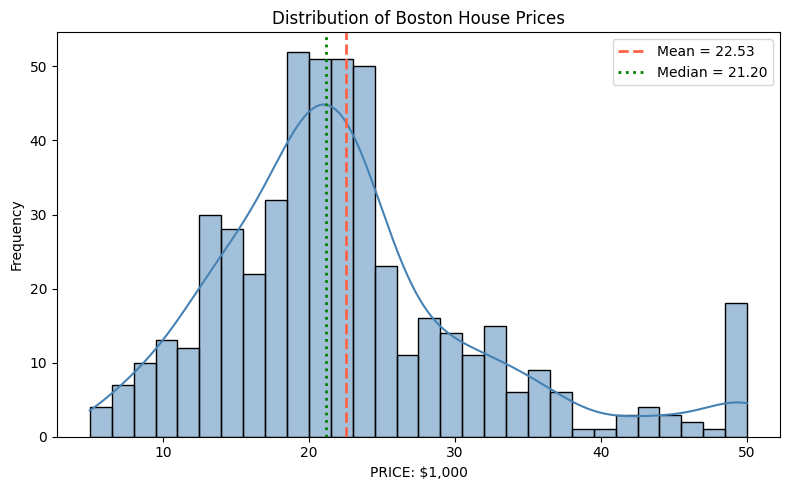

In [ ]:
# =====================================================
# PRICE 히스토그램
# =====================================================

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="PRICE",
    bins=30,
    kde=True,
    color="steelblue"
)

plt.axvline(
    df["PRICE"].mean(),
    color="tomato",
    linestyle="--",
    linewidth=2,
    label=f'Mean = {df["PRICE"].mean():.2f}'
)

plt.axvline(
    df["PRICE"].median(),
    color="green",
    linestyle=":",
    linewidth=2,
    label=f'Median = {df["PRICE"].median():.2f}'
)

plt.title("Distribution of Boston House Prices")
plt.xlabel("PRICE: $1,000")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()


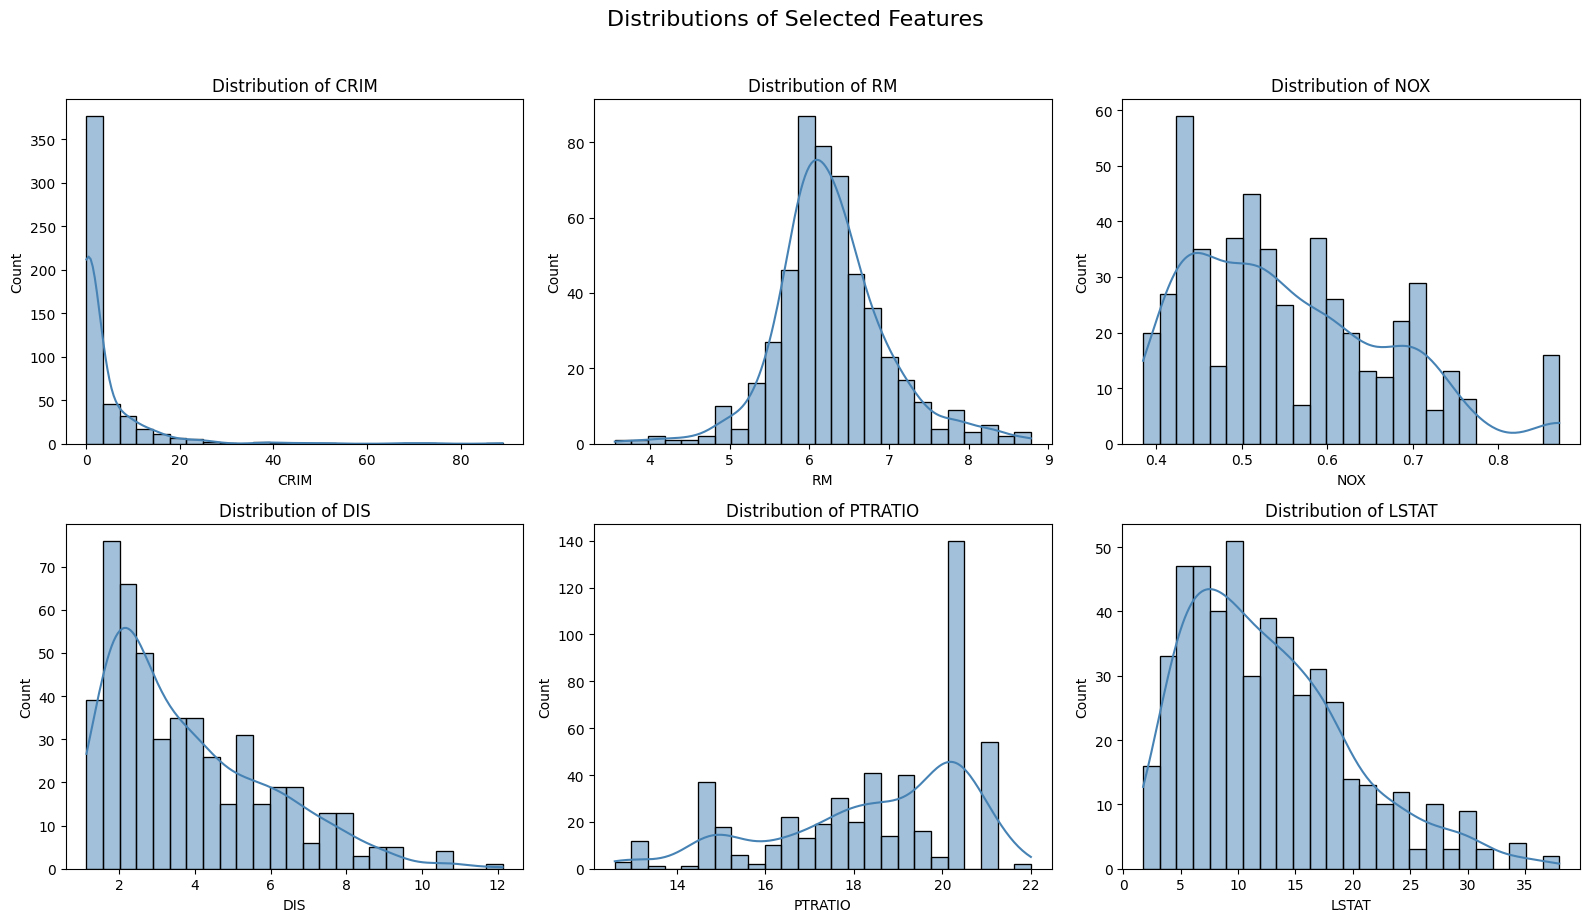

In [ ]:
# =====================================================
# 주요 변수 Histogram
# =====================================================

selected_features = [
    "CRIM",
    "RM",
    "NOX",
    "DIS",
    "PTRATIO",
    "LSTAT"
]

fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(16, 9)
)

axes = axes.ravel()

for ax, feature in zip(axes, selected_features):

    sns.histplot(
        data=df,
        x=feature,
        bins=25,
        kde=True,
        color="steelblue",
        ax=ax
    )

    ax.set_title(f"Distribution of {feature}")

plt.suptitle(
    "Distributions of Selected Features",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()


In [ ]:
# =====================================================
# 상관계수 계산
# =====================================================

correlation_matrix = df.corr(
    method="pearson"
)

display(correlation_matrix.round(3))


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,PRICE
CRIM,1.000,-0.200,0.407,-0.056,0.421,-0.219,0.353,-0.380,0.626,0.583,0.290,-0.385,0.456,-0.388
ZN,-0.200,1.000,-0.534,-0.043,-0.517,0.312,-0.570,0.664,-0.312,-0.315,-0.392,0.176,-0.413,0.360
INDUS,0.407,-0.534,1.000,0.063,0.764,-0.392,0.645,-0.708,0.595,0.721,0.383,-0.357,0.604,-0.484
CHAS,-0.056,-0.043,0.063,1.000,0.091,0.091,0.087,-0.099,-0.007,-0.036,-0.122,0.049,-0.054,0.175
NOX,0.421,-0.517,0.764,0.091,1.000,-0.302,0.731,-0.769,0.611,0.668,0.189,-0.380,0.591,-0.427
RM,-0.219,0.312,-0.392,0.091,-0.302,1.000,-0.240,0.205,-0.210,-0.292,-0.356,0.128,-0.614,0.695
AGE,0.353,-0.570,0.645,0.087,0.731,-0.240,1.000,-0.748,0.456,0.506,0.262,-0.274,0.602,-0.377
DIS,-0.380,0.664,-0.708,-0.099,-0.769,0.205,-0.748,1.000,-0.495,-0.534,-0.232,0.292,-0.497,0.250
RAD,0.626,-0.312,0.595,-0.007,0.611,-0.210,0.456,-0.495,1.000,0.910,0.465,-0.444,0.489,-0.382
TAX,0.583,-0.315,0.721,-0.036,0.668,-0.292,0.506,-0.534,0.910,1.000,0.461,-0.442,0.544,-0.469


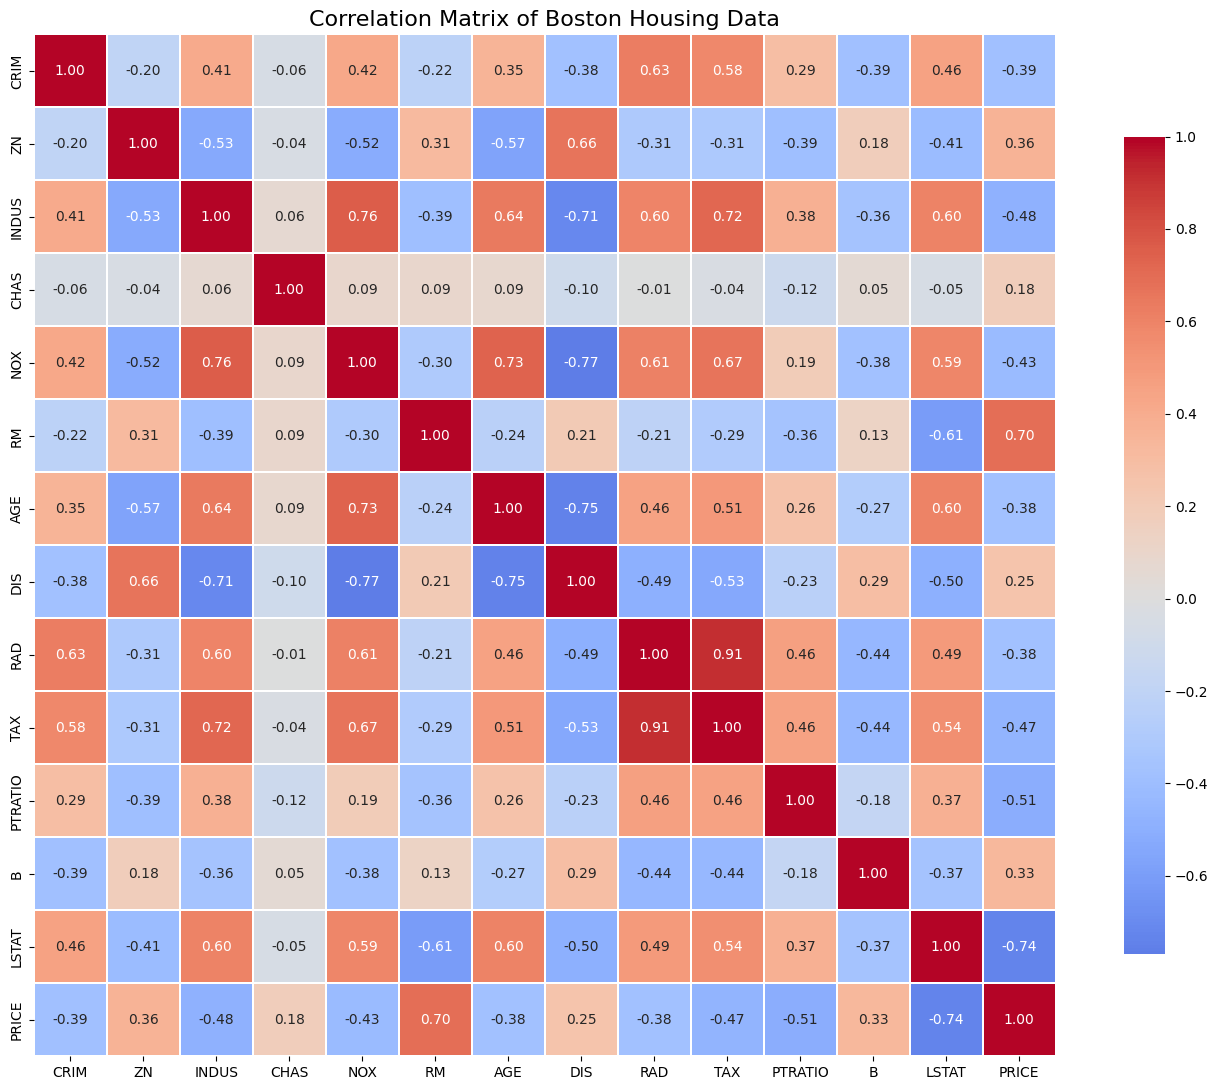

In [ ]:
# =====================================================
# 상관관계 Heatmap
# =====================================================

plt.figure(figsize=(14, 11))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    linewidths=0.3,
    cbar_kws={
        "shrink": 0.8
    }
)

plt.title(
    "Correlation Matrix of Boston Housing Data",
    fontsize=16
)

plt.tight_layout()
plt.show()


In [ ]:
# =====================================================
# PRICE와 각 변수의 상관관계
# =====================================================

price_correlation = (
    correlation_matrix["PRICE"]
    .drop("PRICE")
    .sort_values(ascending=False)
)

print("PRICE와 입력변수의 상관계수:")
display(
    price_correlation
    .to_frame(name="Correlation")
    .round(3)
)


PRICE와 입력변수의 상관계수:


,Correlation
RM,0.695
ZN,0.360
B,0.333
DIS,0.250
CHAS,0.175
AGE,-0.377
RAD,-0.382
CRIM,-0.388
NOX,-0.427
TAX,-0.469


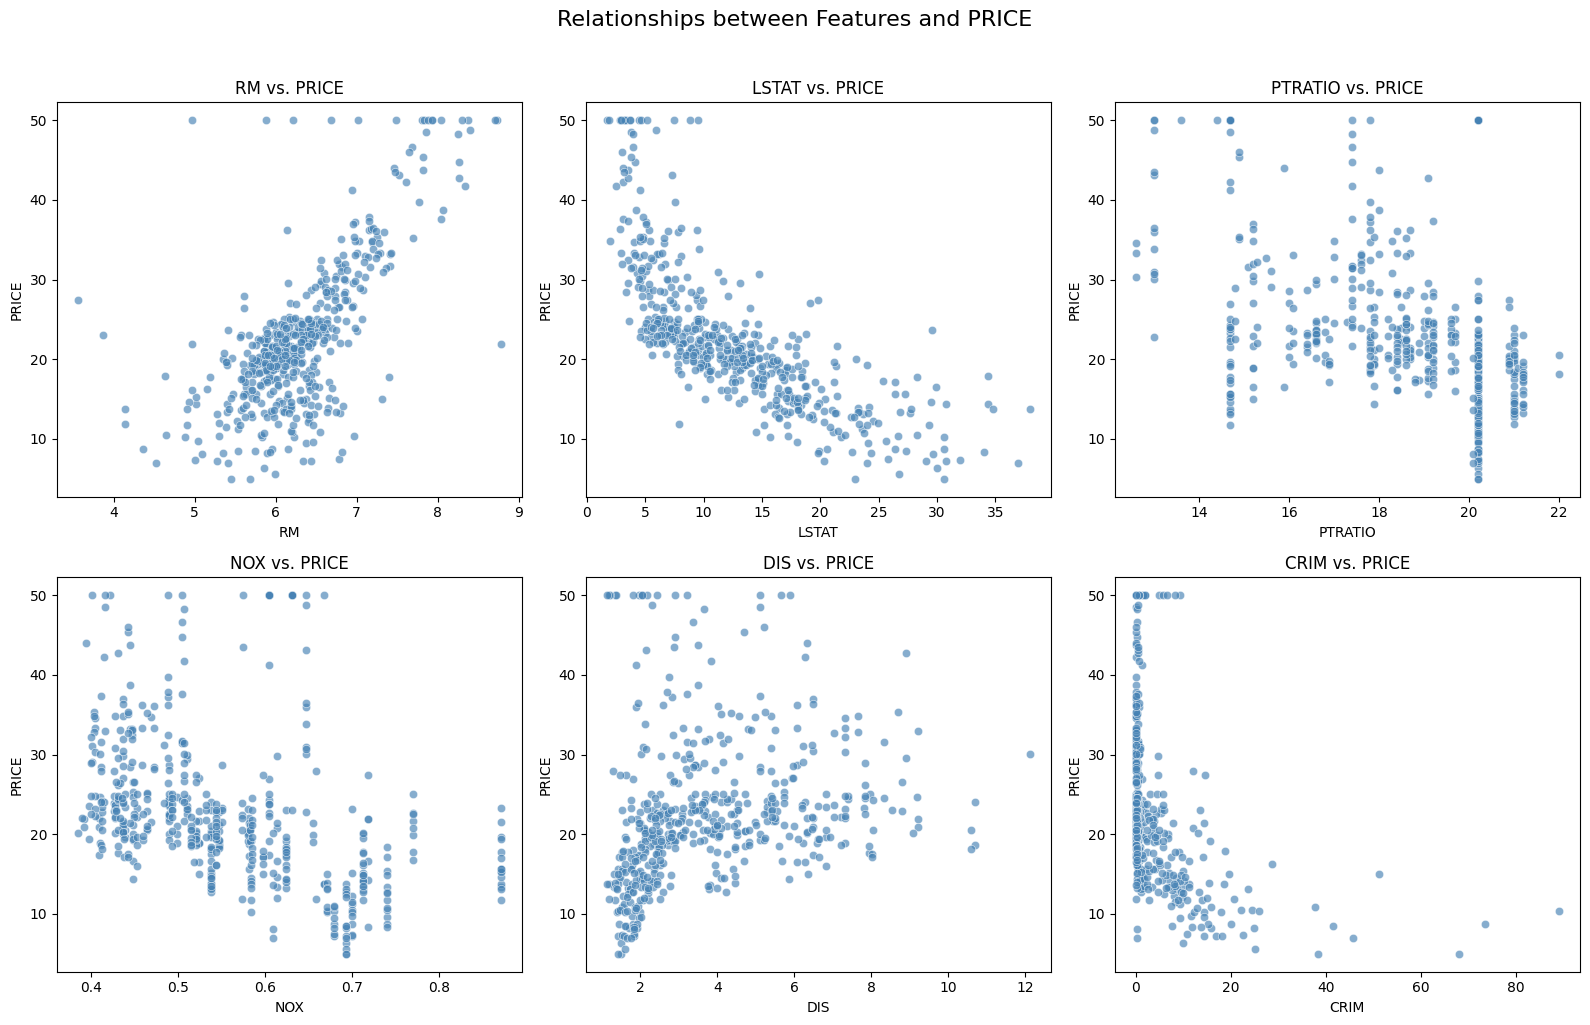

In [ ]:
# =====================================================
# 주요 변수와 PRICE 산점도
# =====================================================

scatter_features = [
    "RM",
    "LSTAT",
    "PTRATIO",
    "NOX",
    "DIS",
    "CRIM"
]

fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(16, 10)
)

axes = axes.ravel()

for ax, feature in zip(
    axes,
    scatter_features
):

    sns.scatterplot(
        data=df,
        x=feature,
        y="PRICE",
        alpha=0.65,
        color="steelblue",
        ax=ax
    )

    ax.set_title(f"{feature} vs. PRICE")

plt.suptitle(
    "Relationships between Features and PRICE",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()


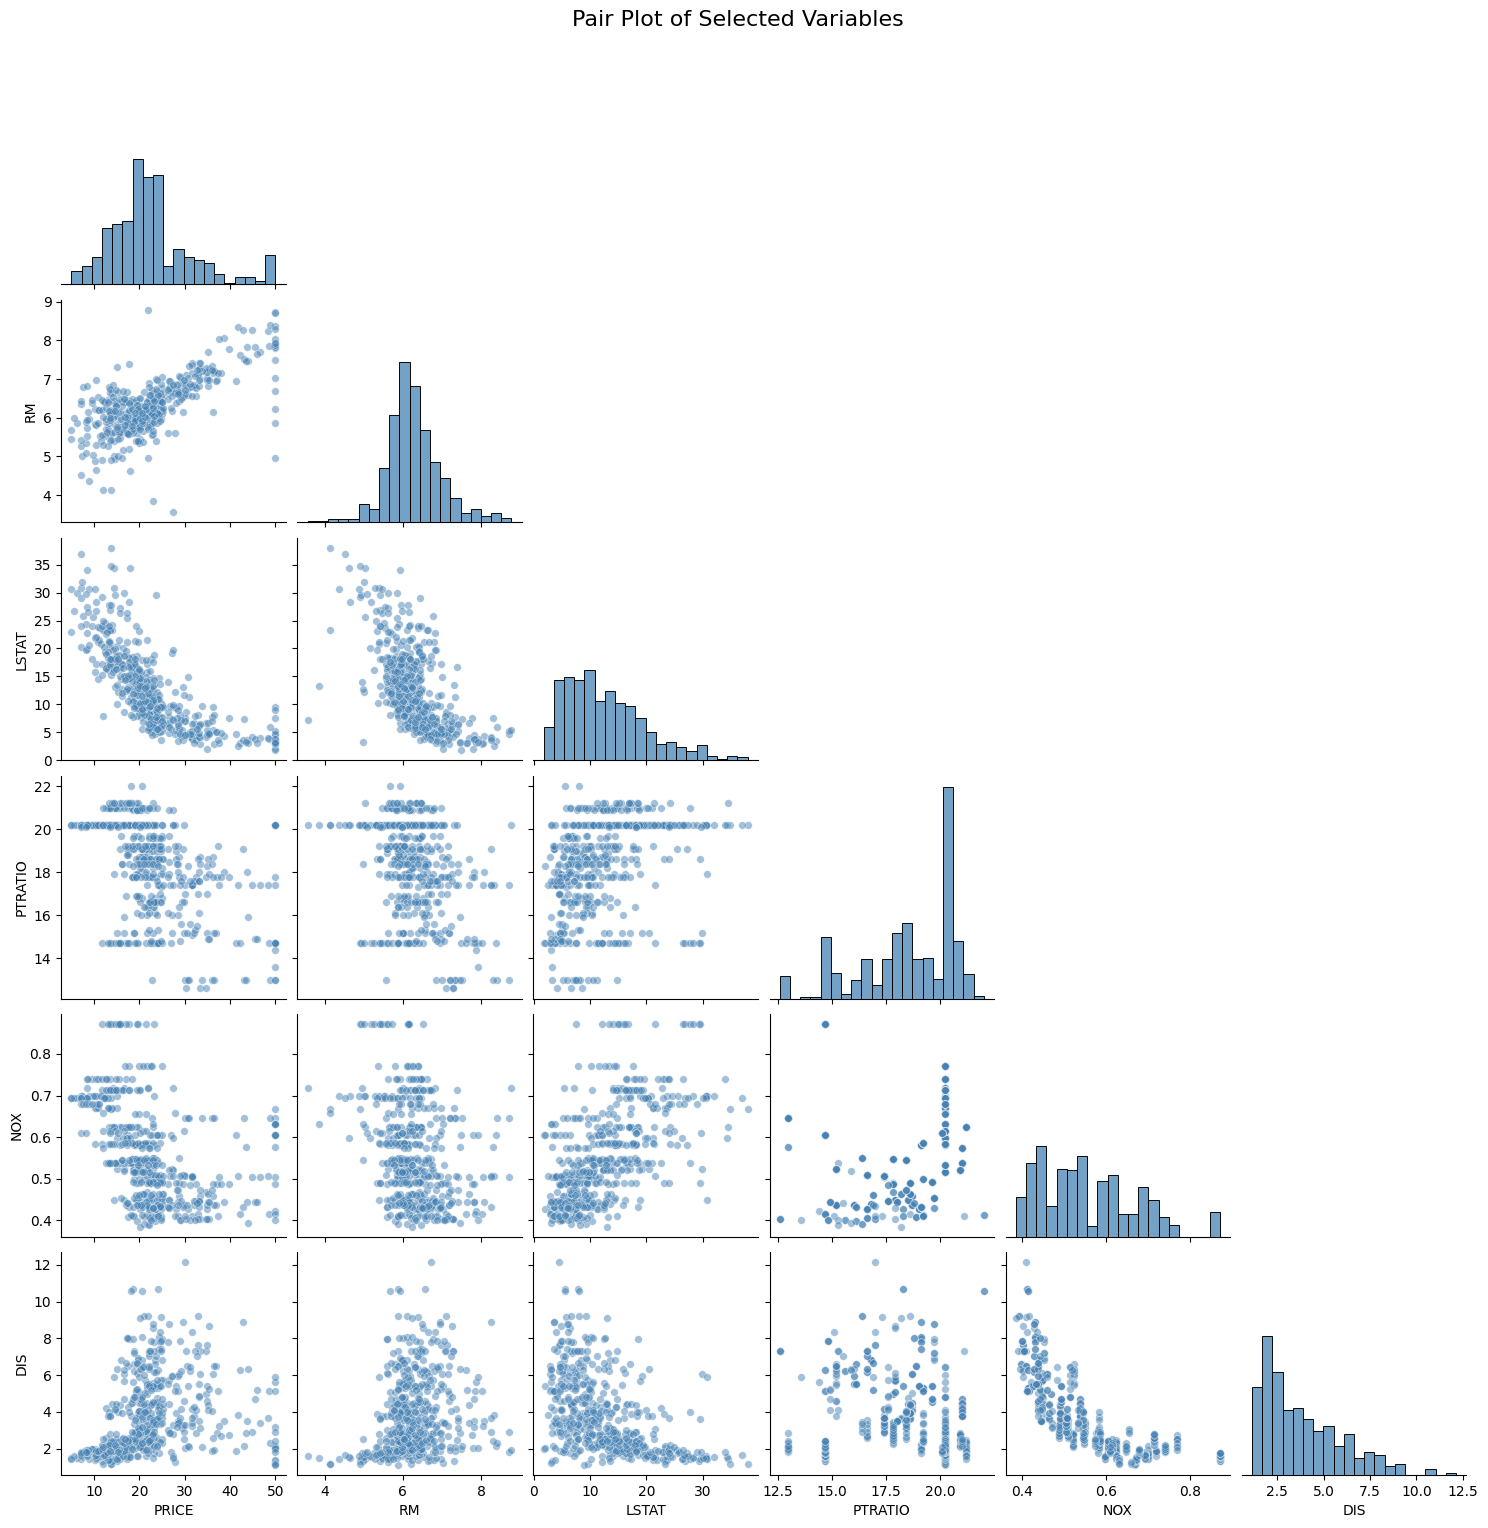

In [ ]:
# =====================================================
# 주요 변수 Pair plot
# =====================================================

pairplot_features = [
    "PRICE",
    "RM",
    "LSTAT",
    "PTRATIO",
    "NOX",
    "DIS"
]

pairplot_df = df[
    pairplot_features
].copy()

sns.pairplot(
    pairplot_df,
    corner=True,
    diag_kind="hist",
    plot_kws={
        "alpha": 0.5,
        "s": 30,
        "color": "steelblue"
    },
    diag_kws={
        "bins": 20,
        "color": "steelblue"
    }
)

plt.suptitle(
    "Pair Plot of Selected Variables",
    fontsize=16,
    y=1.02
)

plt.show()


In [ ]:
# =====================================================
# 입력변수 간 높은 상관관계 탐색
# =====================================================

feature_correlation = X_data.corr().abs()

# 상관행렬의 상삼각 부분만 선택
upper_triangle = feature_correlation.where(
    np.triu(
        np.ones(feature_correlation.shape),
        k=1
    ).astype(bool)
)

high_correlation_pairs = []

for column in upper_triangle.columns:

    for row in upper_triangle.index:

        corr_value = upper_triangle.loc[
            row,
            column
        ]

        if (
            pd.notna(corr_value)
            and corr_value >= 0.7
        ):
            high_correlation_pairs.append({
                "Feature 1": row,
                "Feature 2": column,
                "Absolute Correlation": corr_value
            })

high_corr_df = pd.DataFrame(
    high_correlation_pairs
)

if len(high_corr_df) > 0:

    high_corr_df = high_corr_df.sort_values(
        by="Absolute Correlation",
        ascending=False
    )

    display(high_corr_df.round(3))

else:
    print(
        "절댓값 0.7 이상의 상관관계를 가진 "
        "변수 쌍이 없습니다."
    )


NameError: name 'X_data' is not defined

### 회귀분석

In [ ]:
# =====================================================
# 2. 입력변수 X와 목표변수 y 분리
# =====================================================

# 목표변수: 주택가격
y_target = df['PRICE']

# 독립변수
X_data = df.drop(
    ['PRICE'],
    axis=1,
    inplace=False
)

print('\n입력변수 데이터 크기:', X_data.shape)
print('목표변수 데이터 크기:', y_target.shape)



입력변수 데이터 크기: (506, 13)
목표변수 데이터 크기: (506,)


In [ ]:
# =====================================================
# 3. 훈련셋과 테스트셋 분리
# =====================================================

X_train, X_test, y_train, y_test = train_test_split(
    X_data,
    y_target,
    test_size=0.3,       # 테스트 데이터 약 30%
    random_state=42      # 결과 재현
)

# 회귀의 목표변수는 연속형이므로 stratify 사용하지 않음

print('\n훈련셋 입력 데이터 크기:', X_train.shape)
print('테스트셋 입력 데이터 크기:', X_test.shape)

print('\n훈련셋 목표변수 기술통계:')
print(y_train.describe())

print('\n테스트셋 목표변수 기술통계:')
print(y_test.describe())


훈련셋 입력 데이터 크기: (354, 13)
테스트셋 입력 데이터 크기: (152, 13)

훈련셋 목표변수 기술통계:
count    354.000000
mean      23.015819
std        9.388585
min        5.000000
25%       17.400000
50%       21.750000
75%       26.600000
max       50.000000
Name: PRICE, dtype: float64

테스트셋 목표변수 기술통계:
count    152.000000
mean      21.407895
std        8.660633
min        5.000000
25%       16.325000
50%       20.000000
75%       24.125000
max       50.000000
Name: PRICE, dtype: float64


In [ ]:
# =====================================================
# 4. 선형회귀 모델 생성 및 학습
# =====================================================

lr = LinearRegression()

lr.fit(
    X_train,
    y_train
)

print('\n선형회귀 모델 학습 완료')



선형회귀 모델 학습 완료


In [ ]:
# =====================================================
# 5. 테스트 데이터 예측 및 모델 성능 평가
# =====================================================

y_preds = lr.predict(X_test)


# MSE
mse = mean_squared_error(
    y_test,
    y_preds
)

# RMSE
rmse = np.sqrt(mse)

# MAE
mae = mean_absolute_error(
    y_test,
    y_preds
)

# 결정계수
r2 = r2_score(
    y_test,
    y_preds
)

print('\n모델 성능 평가')
print(f'MAE  : {mae:.3f}')
print(f'MSE  : {mse:.3f}')
print(f'RMSE : {rmse:.3f}')
print(f'R²   : {r2:.3f}')




모델 성능 평가
MAE  : 3.163
MSE  : 21.517
RMSE : 4.639
R²   : 0.711


In [ ]:

# =====================================================
# 6. 절편과 회귀계수 확인
# =====================================================

print('\n절편 값:')
print(np.round(lr.intercept_, 3))

print('\n회귀계수:')
print(np.round(lr.coef_, 3))


절편 값:
31.631

회귀계수:
[-1.3300e-01  3.6000e-02  5.0000e-02  3.1200e+00 -1.5417e+01  4.0570e+00
 -1.1000e-02 -1.3860e+00  2.4300e-01 -9.0000e-03 -9.1100e-01  1.2000e-02
 -5.4700e-01]


In [ ]:
# =====================================================
# 7. 변수별 회귀계수 정리
# =====================================================

coef_df = pd.DataFrame({
    'Feature': X_data.columns,
    'Coefficient': lr.coef_
})

coef_df['Absolute Coefficient'] = (
    coef_df['Coefficient'].abs()
)

coef_df = coef_df.sort_values(
    by='Absolute Coefficient',
    ascending=False
).reset_index(drop=True)

print(coef_df.round(3))

    Feature  Coefficient  Absolute Coefficient
0       NOX      -15.417                15.417
1        RM        4.057                 4.057
2      CHAS        3.120                 3.120
3       DIS       -1.386                 1.386
4   PTRATIO       -0.911                 0.911
5     LSTAT       -0.547                 0.547
6       RAD        0.243                 0.243
7      CRIM       -0.133                 0.133
8     INDUS        0.050                 0.050
9        ZN        0.036                 0.036
10        B        0.012                 0.012
11      AGE       -0.011                 0.011
12      TAX       -0.009                 0.009


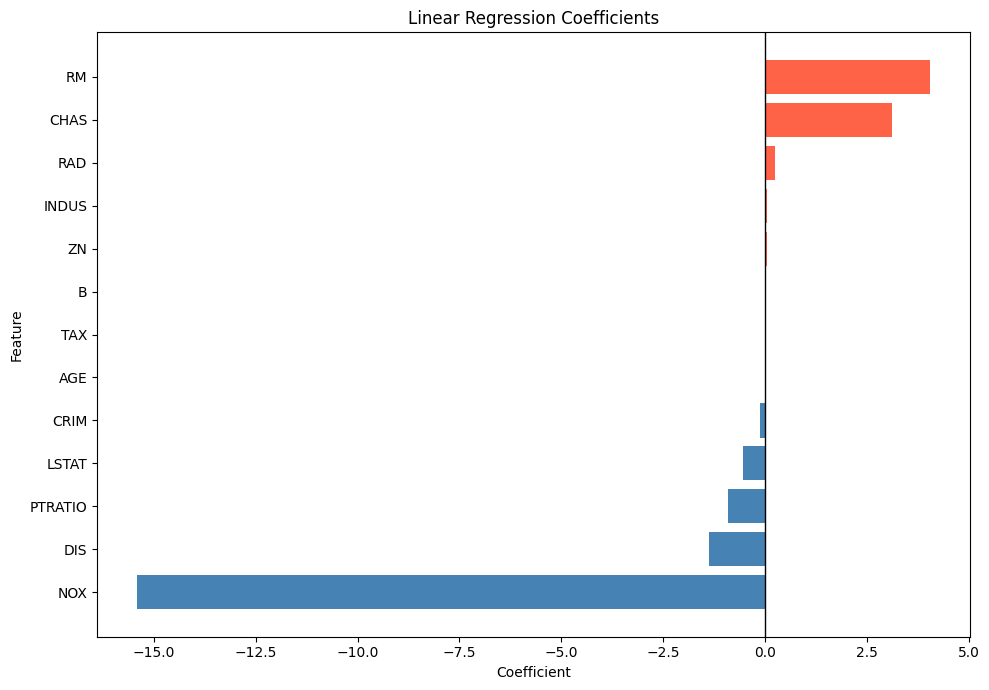

In [ ]:
# =====================================================
# 8. 회귀계수 시각화
# =====================================================

coef_plot_df = coef_df.sort_values(
    by='Coefficient'
)

colors = [
    'tomato' if value > 0 else 'steelblue'
    for value in coef_plot_df['Coefficient']
]

plt.figure(figsize=(10, 7))

plt.barh(
    coef_plot_df['Feature'],
    coef_plot_df['Coefficient'],
    color=colors
)

plt.axvline(
    x=0,
    color='black',
    linewidth=1
)

plt.title('Linear Regression Coefficients')
plt.xlabel('Coefficient')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()


In [ ]:
# =====================================================
# 9. 실제값과 예측값 비교
# =====================================================

prediction_df = pd.DataFrame({
    'Actual': y_test.to_numpy(),
    'Predicted': y_preds
})

prediction_df['Residual'] = (
    prediction_df['Actual']
    - prediction_df['Predicted']
)

print(prediction_df.head(10).round(3))


   Actual  Predicted  Residual
0    23.6     28.649    -5.049
1    32.4     36.495    -4.095
2    13.6     15.411    -1.811
3    22.8     25.403    -2.603
4    16.1     18.855    -2.755
5    20.0     23.147    -3.147
6    17.8     17.392     0.408
7    14.0     14.079    -0.079
8    19.6     23.037    -3.437
9    16.8     20.599    -3.799


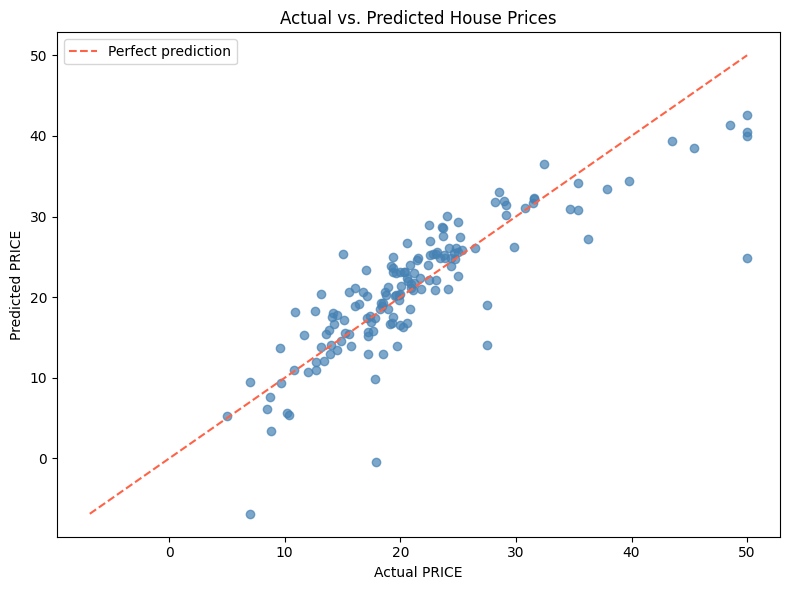

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_preds,
    alpha=0.7,
    color='steelblue'
)

minimum = min(
    y_test.min(),
    y_preds.min()
)

maximum = max(
    y_test.max(),
    y_preds.max()
)

# 실제값과 예측값이 동일한 기준선
plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle='--',
    color='tomato',
    label='Perfect prediction'
)

plt.title('Actual vs. Predicted House Prices')
plt.xlabel('Actual PRICE')
plt.ylabel('Predicted PRICE')
plt.legend()
plt.tight_layout()
plt.show()


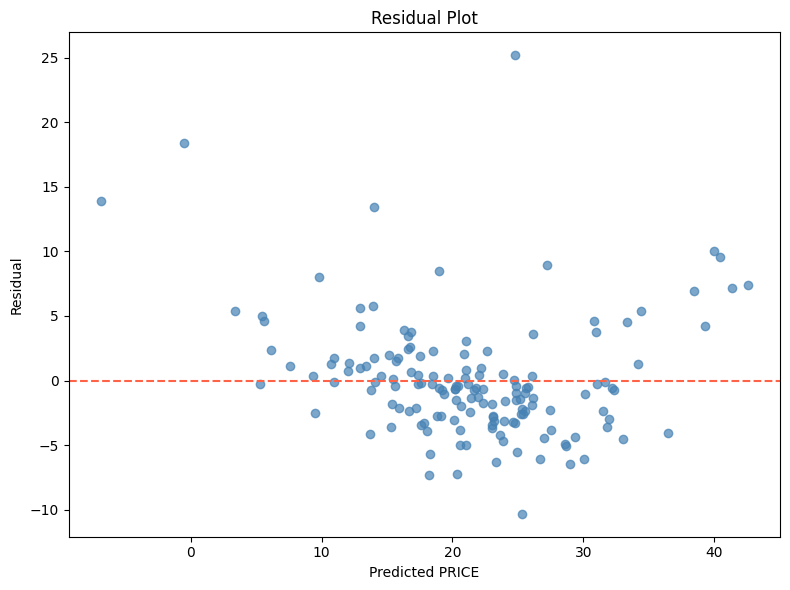

In [ ]:
# =====================================================
# 10. 잔차 분석
# =====================================================

residuals = (
    y_test.to_numpy()
    - y_preds
)

plt.figure(figsize=(8, 6))

plt.scatter(
    y_preds,
    residuals,
    alpha=0.7,
    color='steelblue'
)

plt.axhline(
    y=0,
    color='tomato',
    linestyle='--'
)

plt.title('Residual Plot')
plt.xlabel('Predicted PRICE')
plt.ylabel('Residual')
plt.tight_layout()
plt.show()


# **데이터셋 분할**

## Hold-out

In [ ]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split

# 불균형 데이터 생성: 정상 99%, 이상 1%
X, y = make_classification(
    n_samples=1000,
    n_classes=2,
    weights=[0.99, 0.01],
    flip_y=0,
    random_state=1
)

# 훈련셋 70%, 테스트셋 30% 계층 분할
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    stratify=None,
    random_state=1
)

# 클래스별 개수
train_0 = len(y_train[y_train == 0])
train_1 = len(y_train[y_train == 1])
test_0 = len(y_test[y_test == 0])
test_1 = len(y_test[y_test == 1])

# 클래스별 비율
train_ratio_0 = train_0*100 / len(y_train)
train_ratio_1 = train_1*100 / len(y_train)
test_ratio_0 = test_0*100 / len(y_test)
test_ratio_1 = test_1*100 / len(y_test)

# f-string 출력
print(
    f"Train: 0={train_0} ({train_ratio_0:.2f}%), "
    f"1={train_1} ({train_ratio_1:.2f}%), "
    f"Test: 0={test_0} ({test_ratio_0:.2f}%), "
    f"1={test_1} ({test_ratio_1:.2f}%)"
)

Train: 0=692 (98.86%), 1=8 (1.14%), Test: 0=298 (99.33%), 1=2 (0.67%)


## Stratified Hold-out

In [ ]:
# 훈련셋 70%, 테스트셋 30% 계층 분할
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    stratify=y,
    random_state=1
)

# 클래스별 개수
train_0 = len(y_train[y_train == 0])
train_1 = len(y_train[y_train == 1])
test_0 = len(y_test[y_test == 0])
test_1 = len(y_test[y_test == 1])

# 클래스별 비율
train_ratio_0 = train_0*100 / len(y_train)
train_ratio_1 = train_1*100 / len(y_train)
test_ratio_0 = test_0*100 / len(y_test)
test_ratio_1 = test_1*100 / len(y_test)

# f-string 출력
print(
    f"Train: 0={train_0} ({train_ratio_0:.2f}%), "
    f"1={train_1} ({train_ratio_1:.2f}%), "
    f"Test: 0={test_0} ({test_ratio_0:.2f}%), "
    f"1={test_1} ({test_ratio_1:.2f}%)"
)

Train: 0=693 (99.00%), 1=7 (1.00%), Test: 0=297 (99.00%), 1=3 (1.00%)


## Stratified Cross-validation

In [ ]:
from sklearn.datasets import make_classification
from sklearn.model_selection import StratifiedKFold

# 불균형 데이터 생성: 클래스 0은 99%, 클래스 1은 1%
X, y = make_classification(
    n_samples=1000,
    n_classes=2,
    weights=[0.99, 0.01],
    flip_y=0,
    random_state=1
)

# Stratified 5-Fold 설정
skfold = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=1
)

# Fold별 클래스 분포 확인
for fold, (train_ix, valid_ix) in enumerate(
    skfold.split(X, y),
    start=1
):
    # 행 선택
    X_fold_train = X[train_ix]
    X_fold_valid = X[valid_ix]

    y_fold_train = y[train_ix]
    y_fold_valid = y[valid_ix]

    # 클래스별 개수
    train_0 = sum(y_fold_train == 0)
    train_1 = sum(y_fold_train == 1)

    valid_0 = sum(y_fold_valid == 0)
    valid_1 = sum(y_fold_valid == 1)

    # 클래스별 비율
    train_ratio_0 = train_0 / len(y_fold_train) * 100
    train_ratio_1 = train_1 / len(y_fold_train) * 100

    valid_ratio_0 = valid_0 / len(y_fold_valid) * 100
    valid_ratio_1 = valid_1 / len(y_fold_valid) * 100

    # 결과 출력
    print(f"Fold {fold}")
    print(
        f"  Train: 0={train_0} ({train_ratio_0:.2f}%), "
        f"1={train_1} ({train_ratio_1:.2f}%)",
        f"  Valid: 0={valid_0} ({valid_ratio_0:.2f}%), "
        f"1={valid_1} ({valid_ratio_1:.2f}%)"
    )


Fold 1
  Train: 0=792 (99.00%), 1=8 (1.00%)   Valid: 0=198 (99.00%), 1=2 (1.00%)
Fold 2
  Train: 0=792 (99.00%), 1=8 (1.00%)   Valid: 0=198 (99.00%), 1=2 (1.00%)
Fold 3
  Train: 0=792 (99.00%), 1=8 (1.00%)   Valid: 0=198 (99.00%), 1=2 (1.00%)
Fold 4
  Train: 0=792 (99.00%), 1=8 (1.00%)   Valid: 0=198 (99.00%), 1=2 (1.00%)
Fold 5
  Train: 0=792 (99.00%), 1=8 (1.00%)   Valid: 0=198 (99.00%), 1=2 (1.00%)


# 불균형 데이터 샘플링

##  SMOTE

Counter({np.int64(0): 9900, np.int64(1): 100})


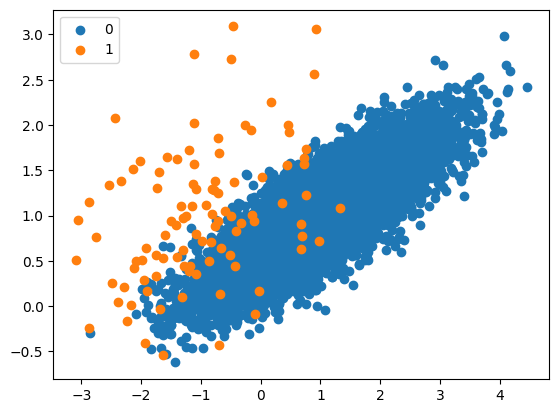

Counter({np.int64(0): 9900, np.int64(1): 9900})


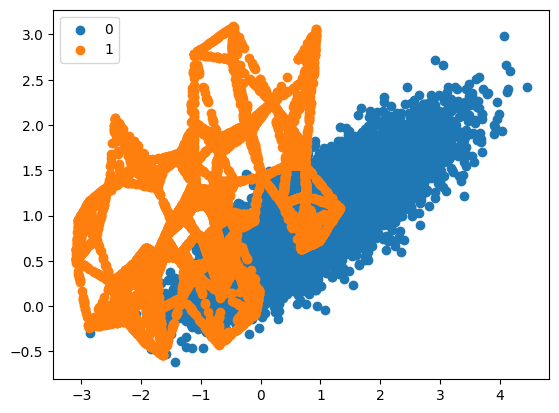

In [ ]:
# Oversample and plot imbalanced dataset with SMOTE
from collections import Counter
from sklearn.datasets import make_classification
from imblearn.over_sampling import SMOTE
from matplotlib import pyplot
from numpy import where

# define dataset
X, y = make_classification(n_samples=10000, n_features=2, n_redundant=0, n_clusters_per_class=1, weights=[0.99], flip_y=0, random_state=1)

# summarize class distribution
counter = Counter(y)
print(counter)
for label, _ in counter.items():
	row_ix = where(y == label)[0]
	pyplot.scatter(X[row_ix, 0], X[row_ix, 1], label=str(label))
pyplot.legend()
pyplot.show()

# transform the dataset
oversample = SMOTE()
X, y = oversample.fit_resample(X, y)

# summarize the new class distribution
counter = Counter(y)
print(counter)

# scatter plot of examples by class label
for label, _ in counter.items():
	row_ix = where(y == label)[0]
	pyplot.scatter(X[row_ix, 0], X[row_ix, 1], label=str(label))
pyplot.legend()
pyplot.show()


## Borderline-SMOTE

Counter({np.int64(0): 9900, np.int64(1): 100})
Counter({np.int64(0): 9900, np.int64(1): 9900})


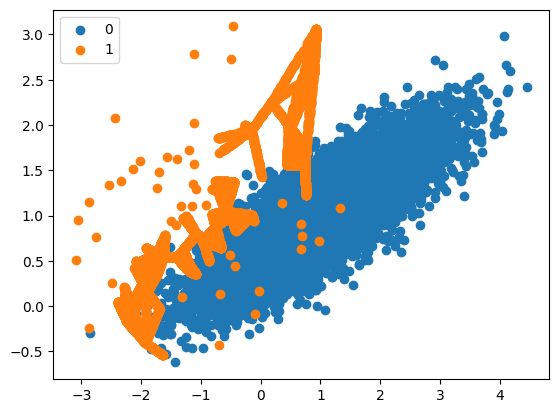

In [ ]:
# Borderline-SMOTE for imbalanced dataset
from collections import Counter
from sklearn.datasets import make_classification
from imblearn.over_sampling import BorderlineSMOTE
from matplotlib import pyplot
from numpy import where
# define dataset
X, y = make_classification(n_samples=10000, n_features=2, n_redundant=0, n_clusters_per_class=1, weights=[0.99], flip_y=0, random_state=1)
# summarize class distribution
counter = Counter(y)
print(counter)

# transform the dataset
oversample = BorderlineSMOTE()
X, y = oversample.fit_resample(X, y)
# summarize the new class distribution
counter = Counter(y)
print(counter)
# scatter plot of examples by class label
for label, _ in counter.items():
	row_ix = where(y == label)[0]
	pyplot.scatter(X[row_ix, 0], X[row_ix, 1], label=str(label))
pyplot.legend()
pyplot.show()


## ADASYN

Counter({np.int64(0): 9900, np.int64(1): 100})
Counter({np.int64(0): 9900, np.int64(1): 9899})


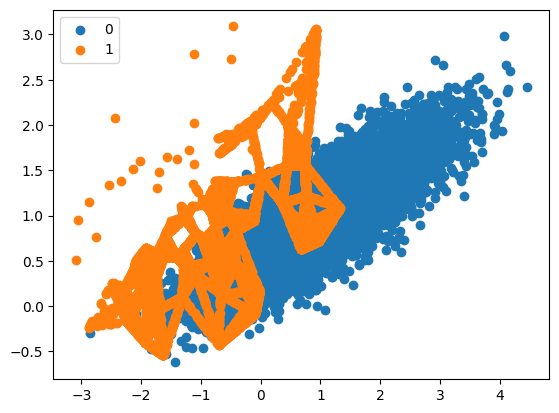

In [ ]:
# Oversample and plot imbalanced dataset with ADASYN
from collections import Counter
from sklearn.datasets import make_classification
from imblearn.over_sampling import ADASYN
from matplotlib import pyplot
from numpy import where
# define dataset
X, y = make_classification(n_samples=10000, n_features=2, n_redundant=0, n_clusters_per_class=1, weights=[0.99], flip_y=0, random_state=1)
# summarize class distribution
counter = Counter(y)
print(counter)

# transform the dataset
oversample = ADASYN()
X, y = oversample.fit_resample(X, y)
# summarize the new class distribution
counter = Counter(y)
print(counter)
# scatter plot of examples by class label
for label, _ in counter.items():
	row_ix = where(y == label)[0]
	pyplot.scatter(X[row_ix, 0], X[row_ix, 1], label=str(label))
pyplot.legend()
pyplot.show()

# [실습] 의사결정나무 성능 비교

## 반복 층화 교차검증

In [ ]:
# # decision tree evaluated on imbalanced dataset
from sklearn.datasets import make_classification
from sklearn.model_selection import (
    cross_validate,
    RepeatedStratifiedKFold
)
from sklearn.tree import DecisionTreeClassifier

# 1. 불균형 데이터 생성
X, y = make_classification(n_samples=10000, n_features=2, n_redundant=0, n_clusters_per_class=1, weights=[0.99], flip_y=0, random_state=1)

# 2. 의사결정나무 모델
model = DecisionTreeClassifier(random_state=42)

# 3. 반복 층화 교차검증
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=1)

# 4. 평가 지표 설정
scoring = {"precision": "precision","recall": "recall","f1": "f1"}

# 5. 교차검증
results = cross_validate(model, X, y, scoring=scoring, cv=cv, n_jobs=-1)

# 6. 각 Fold의 점수 출력
score_df = pd.DataFrame({
    "Precision": results["test_precision"],
    "Recall": results["test_recall"],
    "F1-score": results["test_f1"]
})

score_df.index = [
    f"Evaluation {i}"
    for i in range(1, len(score_df) + 1)
]

display(score_df.round(3))

NameError: name 'pd' is not defined

# SMOTE

In [ ]:
# grid search k value for SMOTE oversampling for imbalanced classification
from numpy import mean
from sklearn.datasets import make_classification
from sklearn.model_selection import cross_validate
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

# 1. 불균형 데이터 생성
X, y = make_classification(n_samples=10000, n_features=2, n_redundant=0, n_clusters_per_class=1, weights=[0.99], flip_y=0, random_state=1)

# 2. 의사결정나무 모델
model = DecisionTreeClassifier(random_state=42)

# 3. 반복 층화 교차검증
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=1)

# 4. 평가 지표 설정
scoring = {"precision": "precision","recall": "recall","f1": "f1"}

# 5. 교차검증
results = cross_validate(model, X, y, scoring=scoring, cv=cv, n_jobs=-1)


# [실습] Breast Cancer

## 1차 실습: 기술통계 및 가시화

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from statsmodels.stats.multitest import multipletests

from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore")

sns.set_theme(
    style="whitegrid",
    context="notebook"
)

plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.unicode_minus"] = False

In [3]:
# =========================================================
# 1. 라이브데이터 불러오기
# =========================================================


# Breast Cancer Wisconsin 데이터 불러오기
data = load_breast_cancer(as_frame=True)

X = data.data.copy()
target_original = data.target.copy()

# 원본 데이터
# 0 = malignant, 악성
# 1 = benign, 양성

df = X.copy()

df["diagnosis"] = target_original.map({
    0: "Malignant",
    1: "Benign"
})

# 악성을 1로 표현한 이진 변수
df["malignant"] = (
    target_original == 0
).astype(int)

print("데이터 크기:", df.shape)
print("입력 변수 개수:", X.shape[1])

df.head()

데이터 크기: (569, 32)
입력 변수 개수: 30


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis,malignant
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,Malignant,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,Malignant,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,Malignant,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,Malignant,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,Malignant,1


In [4]:
# =========================================================
# 2. 데이터 구조 확인
# =========================================================

# 데이터 크기 및 변수
print("표본 수:", X.shape[0])
print("입력 변수 수:", X.shape[1])

print("\n자료형:")
print(df.dtypes.value_counts())

print("\n변수 이름:")
print(X.columns.tolist())

# 결측값 확인
missing_values = df.isnull().sum()
print("전체 결측값 개수:", missing_values.sum())
print("\n결측값이 있는 변수:")
print(missing_values[missing_values > 0])

표본 수: 569
입력 변수 수: 30

자료형:
float64    30
object      1
int64       1
Name: count, dtype: int64

변수 이름:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']
전체 결측값 개수: 0

결측값이 있는 변수:
Series([], dtype: int64)


           Count  Percentage
diagnosis                   
Benign       357       62.74
Malignant    212       37.26


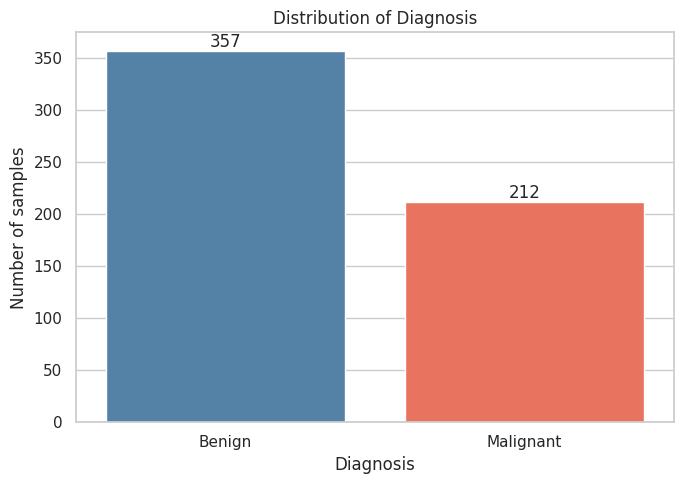

In [5]:
# =========================================================
# 3. 클래스 분포 시각화
# =========================================================


# 클래스 분포
class_counts = df["diagnosis"].value_counts()
class_ratios = df["diagnosis"].value_counts(
    normalize=True
) * 100

class_summary = pd.DataFrame({
    "Count": class_counts,
    "Percentage": class_ratios
})

print(class_summary.round(2))

# 클래스 분포 시각화
class_plot_df = (
    df["diagnosis"]
    .value_counts()
    .rename_axis("Diagnosis")
    .reset_index(name="Count")
)

plt.figure(figsize=(7, 5))

ax = sns.barplot(
    data=class_plot_df,
    x="Diagnosis",
    y="Count",
    hue="Diagnosis",
    order=["Benign", "Malignant"],
    palette={
        "Benign": "steelblue",
        "Malignant": "tomato"
    },
    legend=False
)

for container in ax.containers:
    ax.bar_label(container)

plt.title("Distribution of Diagnosis")
plt.xlabel("Diagnosis")
plt.ylabel("Number of samples")
plt.tight_layout()
plt.show()

In [6]:
X.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


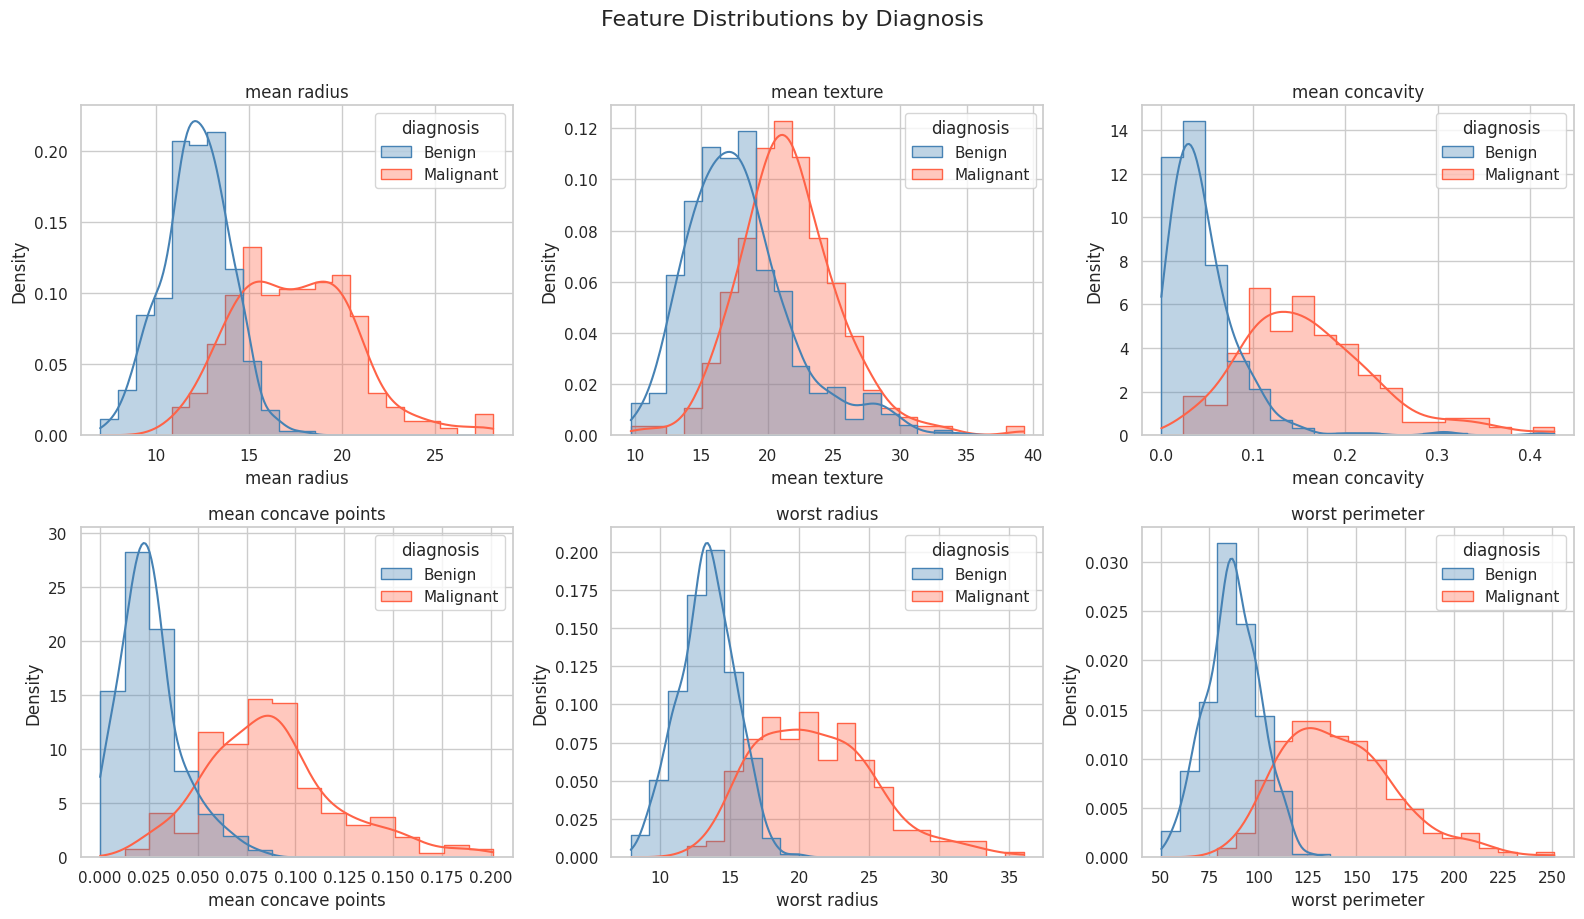

In [17]:
# =========================================================
# 3.  주요 변수의 분포 시각화
# =========================================================

selected_features = [
    "mean radius",
    "mean texture",
    "mean concavity",
    "mean concave points",
    "worst radius",
    "worst perimeter"
]

fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(16, 9)
)

axes = axes.ravel()

for ax, feature in zip(axes, selected_features):

    sns.histplot(
        data=df,
        x=feature,
        hue="diagnosis",
        hue_order=["Benign", "Malignant"],
        palette={
            "Benign": "steelblue",
            "Malignant": "tomato"
        },
        kde=True,
        stat="density",
        common_norm=False,
        element="step",
        alpha=0.35,
        ax=ax
    )

    ax.set_title(feature)

plt.suptitle(
    "Feature Distributions by Diagnosis",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()


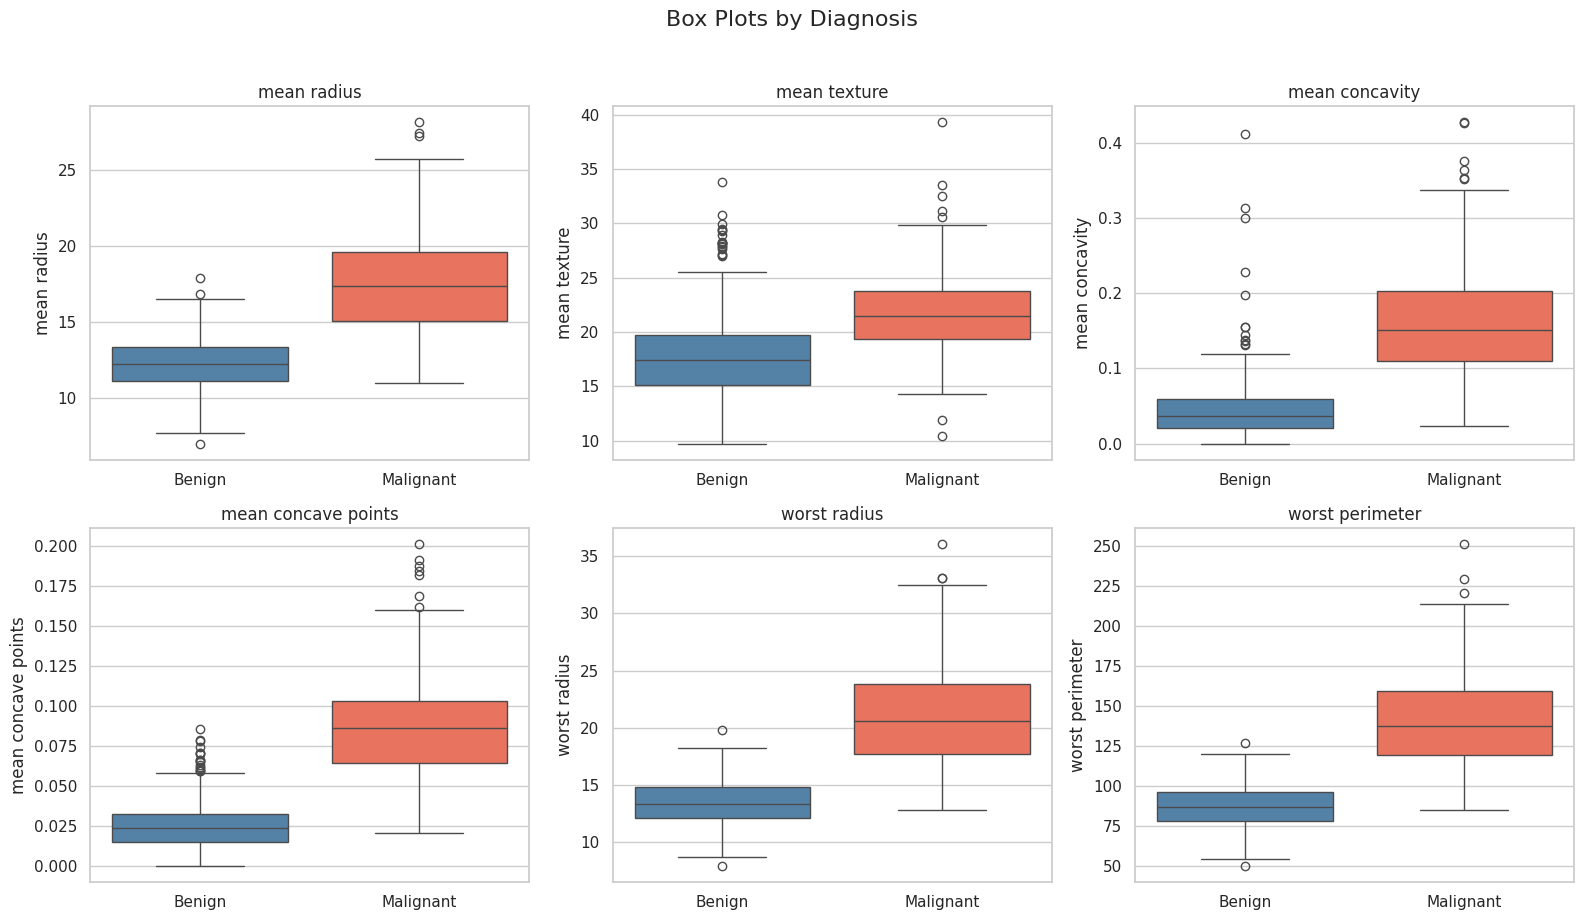

In [8]:
fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(16, 9)
)

axes = axes.ravel()

for ax, feature in zip(axes, selected_features):

    sns.boxplot(
        data=df,
        x="diagnosis",
        y=feature,
        hue="diagnosis",
        order=["Benign", "Malignant"],
        palette={
            "Benign": "steelblue",
            "Malignant": "tomato"
        },
        legend=False,
        ax=ax
    )

    ax.set_title(feature)
    ax.set_xlabel("")

plt.suptitle(
    "Box Plots by Diagnosis",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()


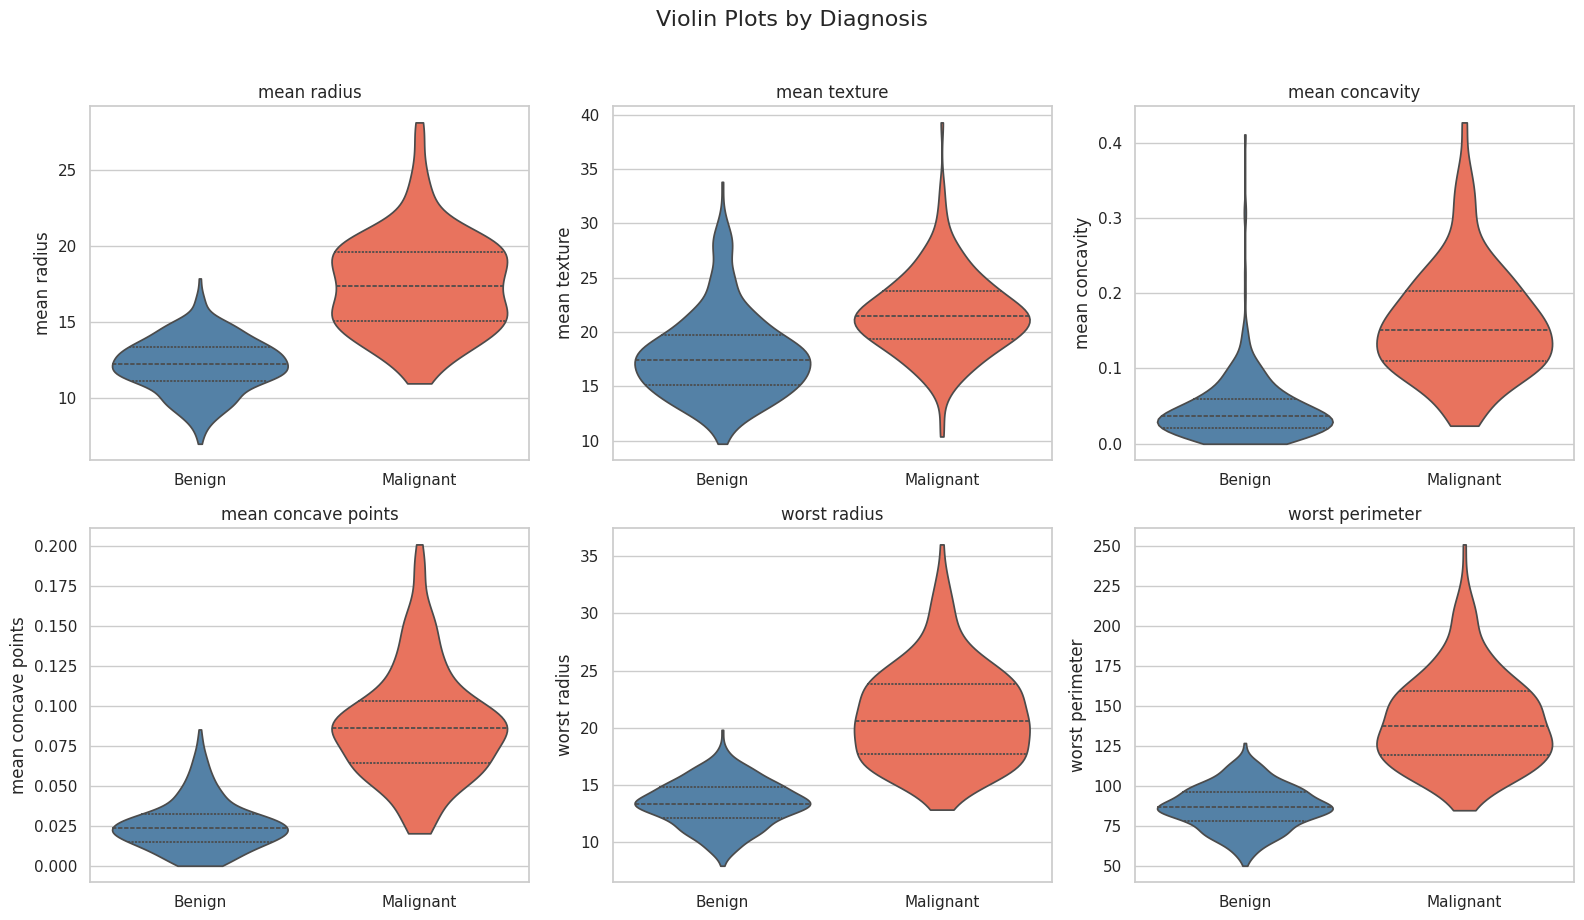

In [9]:
fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(16, 9)
)

axes = axes.ravel()

for ax, feature in zip(axes, selected_features):

    sns.violinplot(
        data=df,
        x="diagnosis",
        y=feature,
        hue="diagnosis",
        order=["Benign", "Malignant"],
        palette={
            "Benign": "steelblue",
            "Malignant": "tomato"
        },
        inner="quartile",
        cut=0,
        legend=False,
        ax=ax
    )

    ax.set_title(feature)
    ax.set_xlabel("")

plt.suptitle(
    "Violin Plots by Diagnosis",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()


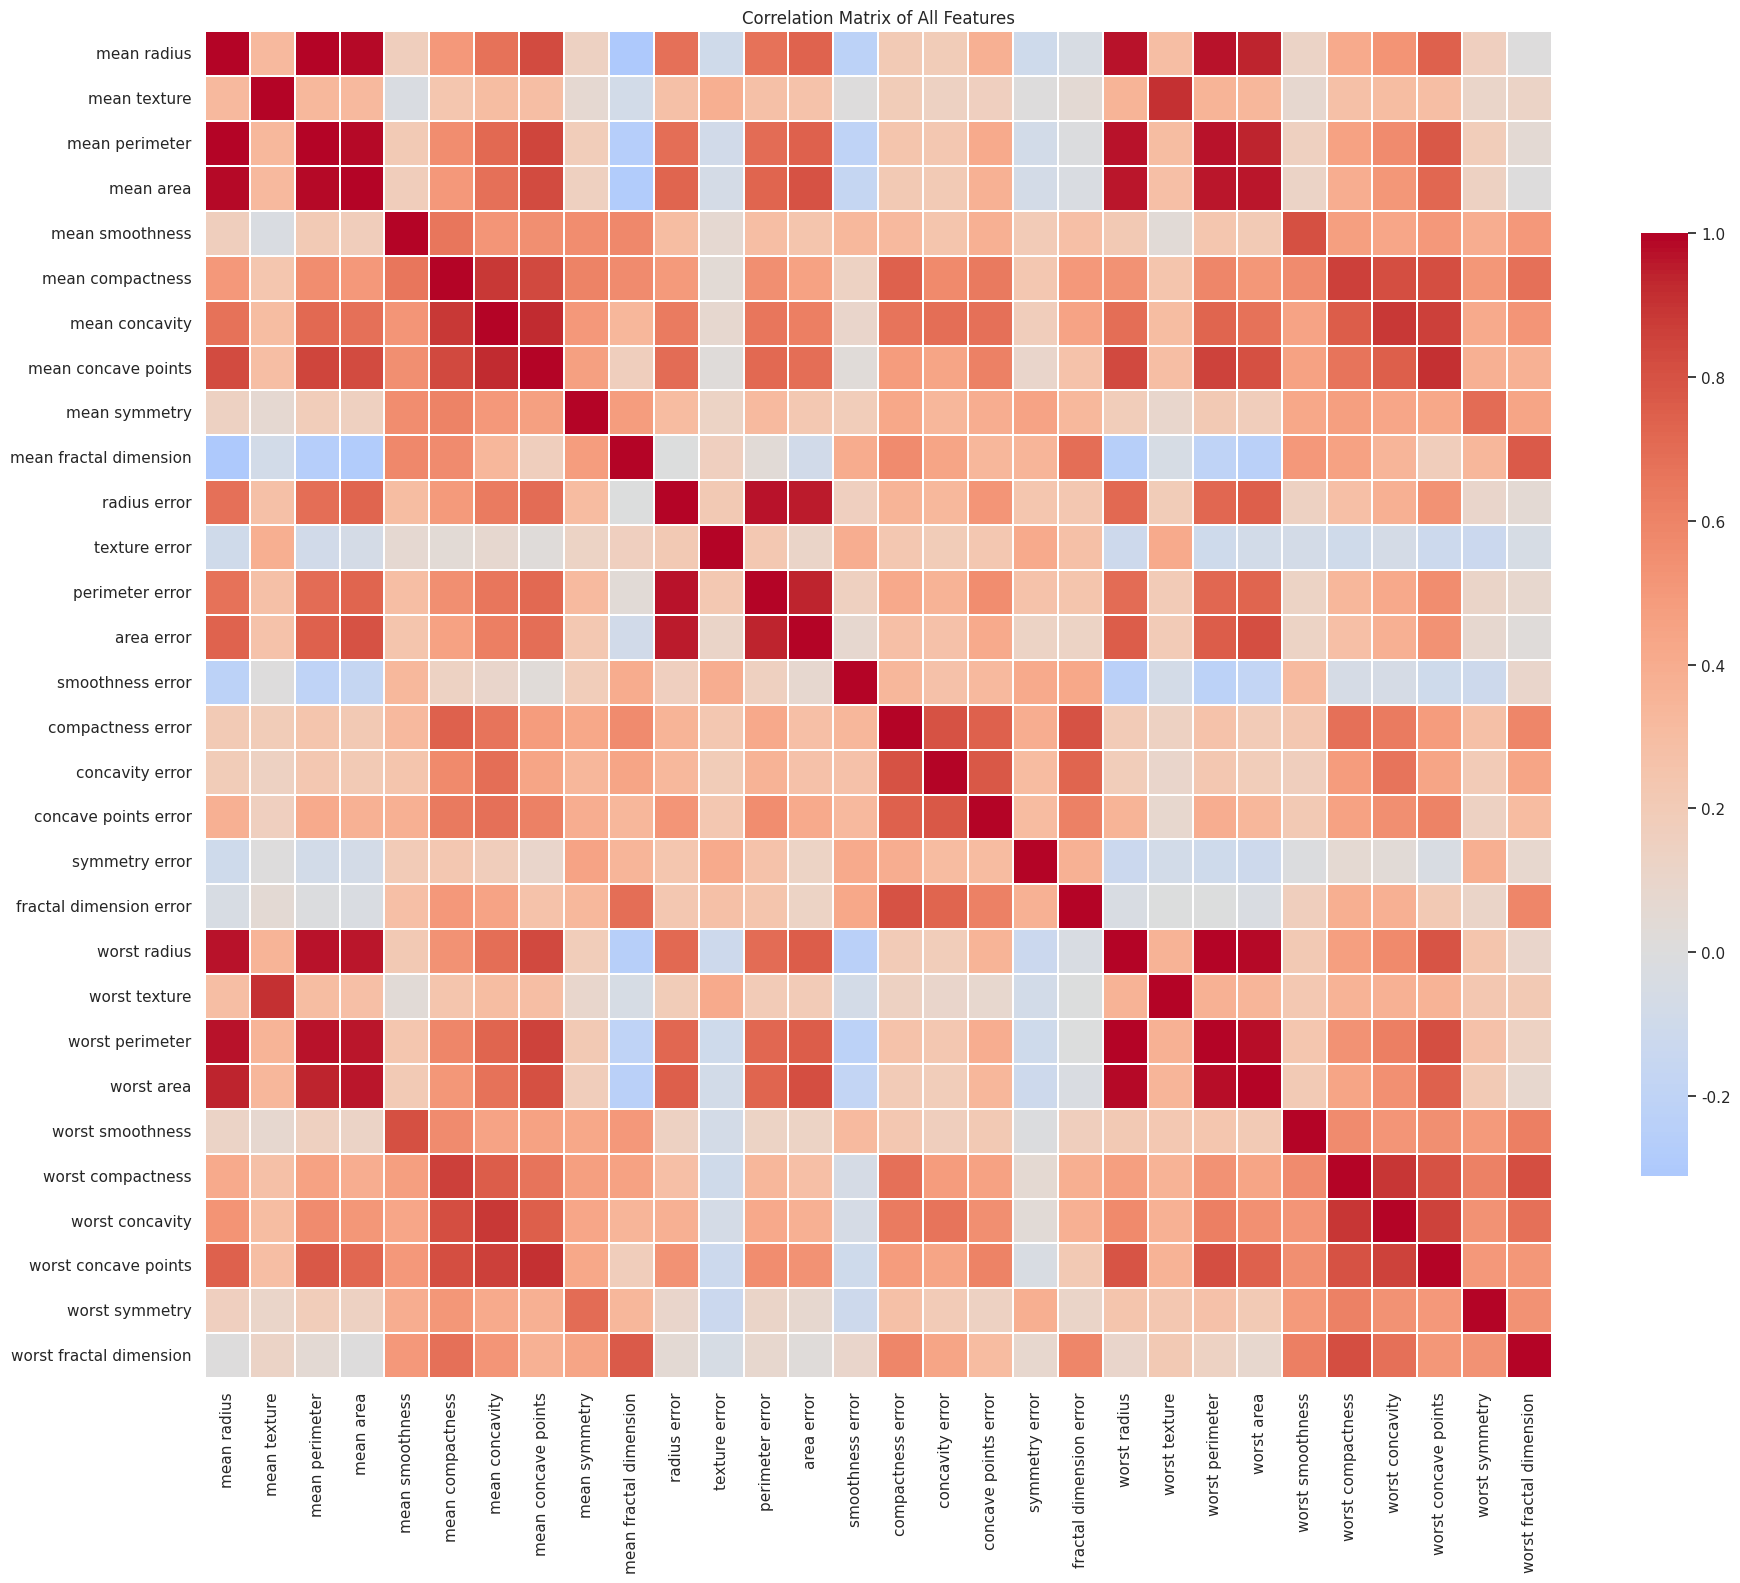

In [10]:
# =========================================================
# 4. 입력변수 간 상관관계 - 전체
# =========================================================

correlation_matrix = X.corr()

plt.figure(figsize=(20, 16))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    square=True,
    linewidths=0.2,
    cbar_kws={
        "shrink": 0.7
    }
)

plt.title("Correlation Matrix of All Features")
plt.tight_layout()
plt.show()


In [11]:
# =========================================================
# 4. 입력변수 간 상관관계 - 전체
# =========================================================

point_biserial_results = []

for feature in X.columns:

    correlation, pvalue = stats.pointbiserialr(
        df["malignant"],
        df[feature]
    )

    point_biserial_results.append({
        "Feature": feature,
        "Correlation": correlation,
        "Absolute Correlation": abs(correlation),
        "p-value": pvalue
    })

point_biserial_df = pd.DataFrame(
    point_biserial_results
)

point_biserial_df["FDR p-value"] = multipletests(
    point_biserial_df["p-value"],
    method="fdr_bh"
)[1]

point_biserial_df = point_biserial_df.sort_values(
    by="Absolute Correlation",
    ascending=False
).reset_index(drop=True)

point_biserial_df.head(15).round(5)

,Feature,Correlation,Absolute Correlation,p-value,FDR p-value
0,worst concave points,0.79357,0.79357,0.0,0.0
1,worst perimeter,0.78291,0.78291,0.0,0.0
2,mean concave points,0.77661,0.77661,0.0,0.0
3,worst radius,0.77645,0.77645,0.0,0.0
4,mean perimeter,0.74264,0.74264,0.0,0.0
5,worst area,0.73383,0.73383,0.0,0.0
6,mean radius,0.73003,0.73003,0.0,0.0
7,mean area,0.70898,0.70898,0.0,0.0
8,mean concavity,0.69636,0.69636,0.0,0.0
9,worst concavity,0.65961,0.65961,0.0,0.0


In [12]:
# =========================================================
# 4. 입력변수 간 상관관계 - 진단과 관련성이 높은 변수만 선택
# =========================================================

top_features = (
    point_biserial_df
    .head(10)["Feature"]
    .tolist()
)

top_features


['worst concave points',
 'worst perimeter',
 'mean concave points',
 'worst radius',
 'mean perimeter',
 'worst area',
 'mean radius',
 'mean area',
 'mean concavity',
 'worst concavity']

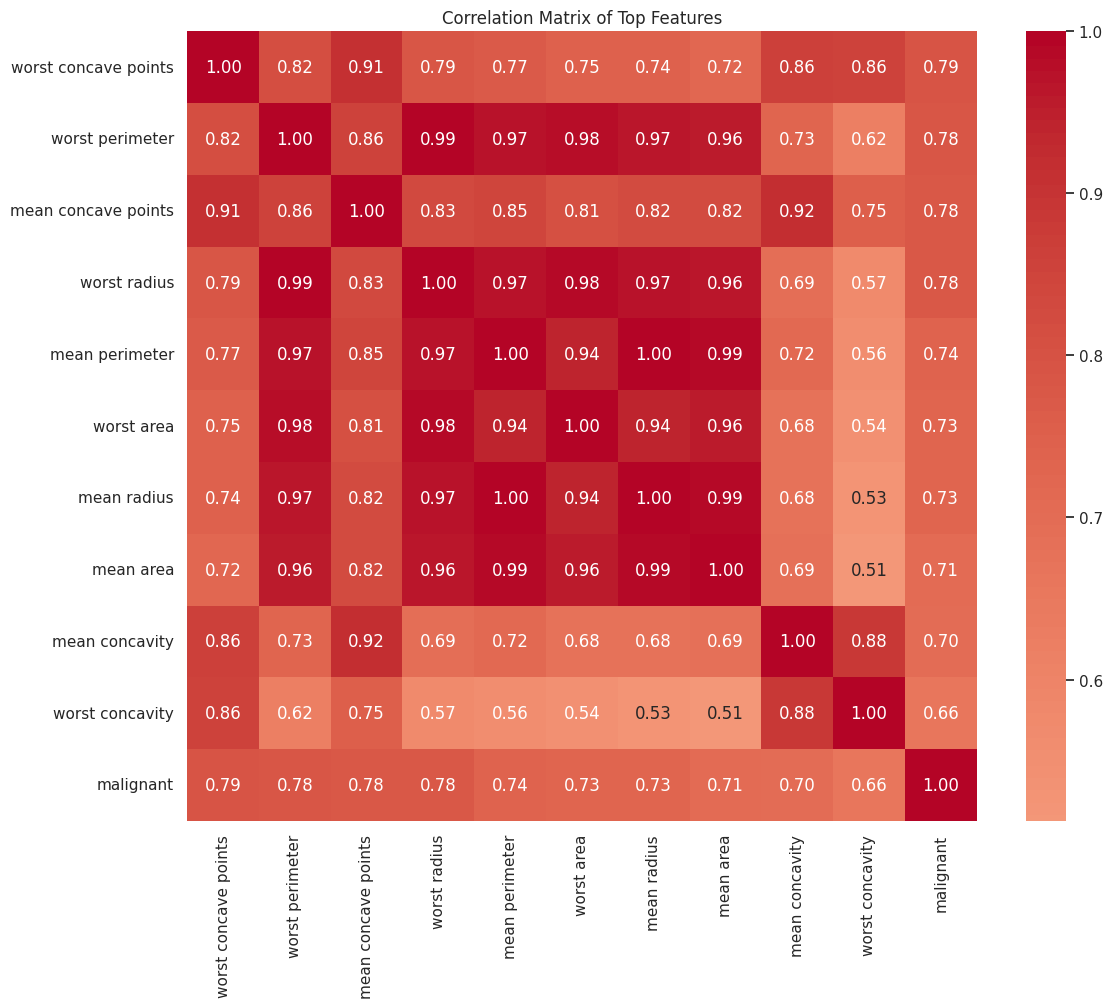

In [13]:
top_correlation_matrix = df[
    top_features + ["malignant"]
].corr()

plt.figure(figsize=(12, 10))

sns.heatmap(
    top_correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True
)

plt.title(
    "Correlation Matrix of Top Features"
)
plt.tight_layout()
plt.show()


In [14]:
# =========================================================
# 5. 입력변수 간 상관관계 - 상관관계가 높은 변수 쌍 찾기
# =========================================================

corr_abs = X.corr().abs()

# 상삼각행렬만 사용
upper_triangle = corr_abs.where(
    np.triu(
        np.ones(corr_abs.shape),
        k=1
    ).astype(bool)
)

high_correlation_pairs = []

for column in upper_triangle.columns:

    for index in upper_triangle.index:

        correlation = upper_triangle.loc[
            index,
            column
        ]

        if (
            pd.notna(correlation)
            and correlation >= 0.90
        ):
            high_correlation_pairs.append({
                "Feature 1": index,
                "Feature 2": column,
                "Absolute Correlation": correlation
            })

high_corr_df = pd.DataFrame(
    high_correlation_pairs
)

high_corr_df = high_corr_df.sort_values(
    by="Absolute Correlation",
    ascending=False
)

print(high_corr_df.round(4))


              Feature 1             Feature 2  Absolute Correlation
0           mean radius        mean perimeter                0.9979
14         worst radius       worst perimeter                0.9937
1           mean radius             mean area                0.9874
2        mean perimeter             mean area                0.9865
18         worst radius            worst area                0.9840
19      worst perimeter            worst area                0.9776
4          radius error       perimeter error                0.9728
12       mean perimeter       worst perimeter                0.9704
7           mean radius          worst radius                0.9695
8        mean perimeter          worst radius                0.9695
11          mean radius       worst perimeter                0.9651
9             mean area          worst radius                0.9627
17            mean area            worst area                0.9592
13            mean area       worst perimeter   

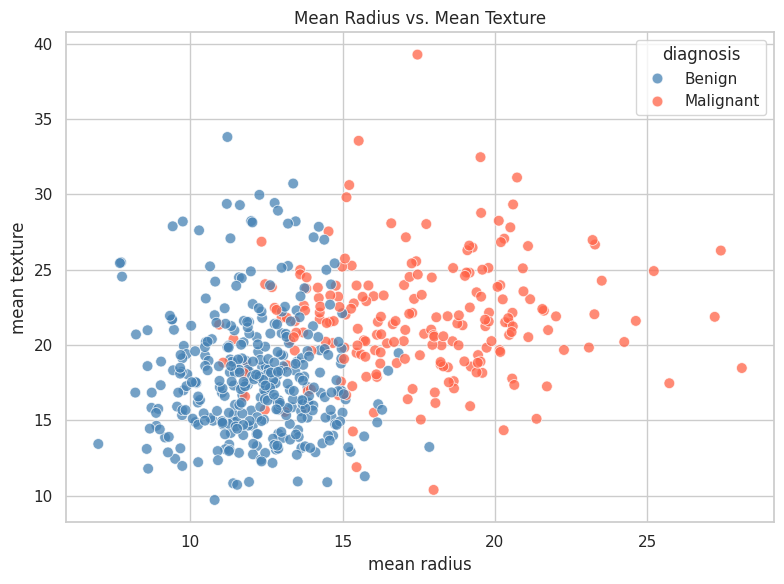

In [15]:
# =========================================================
# 5. 입력변수 간 산점도
# =========================================================
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x="mean radius",
    y="mean texture",
    hue="diagnosis",
    hue_order=["Benign", "Malignant"],
    palette={
        "Benign": "steelblue",
        "Malignant": "tomato"
    },
    alpha=0.75,
    s=60
)

plt.title("Mean Radius vs. Mean Texture")
plt.tight_layout()
plt.show()


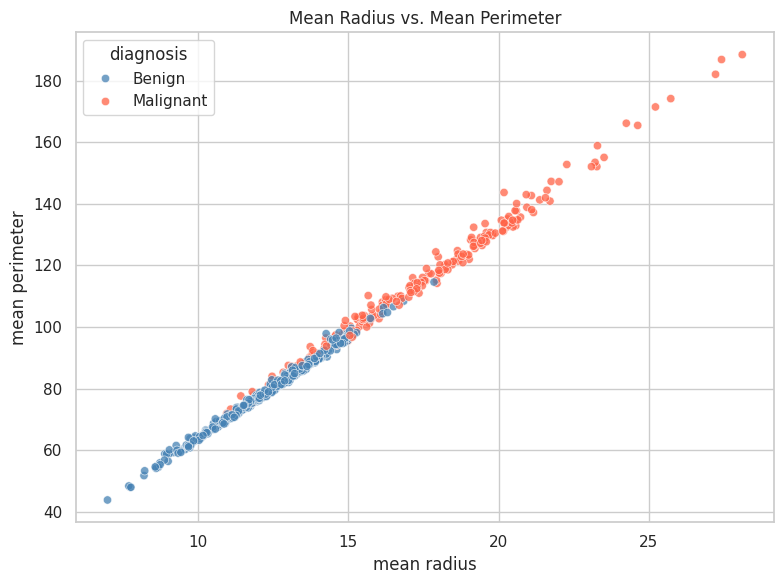

In [16]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x="mean radius",
    y="mean perimeter",
    hue="diagnosis",
    hue_order=["Benign", "Malignant"],
    palette={
        "Benign": "steelblue",
        "Malignant": "tomato"
    },
    alpha=0.75
)

plt.title("Mean Radius vs. Mean Perimeter")
plt.tight_layout()
plt.show()


## 2차 실습: Hold-out 데이터 분할

In [ ]:
# =========================================================
# 1. 라이브러리 불러오기
# =========================================================

import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from lightgbm import LGBMClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay,
    classification_report
)

warnings.filterwarnings("ignore")

# 그래프 스타일
sns.set_theme(style="whitegrid")

# 재현 가능한 실험을 위한 난수 시드
RANDOM_STATE = 42


In [ ]:
# =========================================================
# 2. 데이터 불러오기
# =========================================================

data = load_breast_cancer(as_frame=True)

X = data.data.copy()

# 원본 target
# 0 = malignant(악성)
# 1 = benign(양성)
#
# 악성을 관심 클래스 1로 바꾸기
y = (data.target == 0).astype(int)
y.name = "malignant"

print("입력 데이터 크기:", X.shape)
print("목표 변수 크기:", y.shape)

print("\n변수 이름:")
print(X.columns.tolist())

print("\n클래스 분포:")
print(y.value_counts().sort_index())

print("\n클래스 비율:")
print(y.value_counts(normalize=True).sort_index())


입력 데이터 크기: (569, 30)
목표 변수 크기: (569,)

변수 이름:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']

클래스 분포:
malignant
0    357
1    212
Name: count, dtype: int64

클래스 비율:
malignant
0    0.627417
1    0.372583
Name: proportion, dtype: float64


In [ ]:
# =========================================================
# 3. 데이터 기본 정보 확인
# =========================================================

print(X.head())

print("\n결측값 개수:")
print(X.isnull().sum().sum())

print("\n기술통계:")
print(X.describe().T.head(10))


   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  worst texture  worst perimeter  \
0           

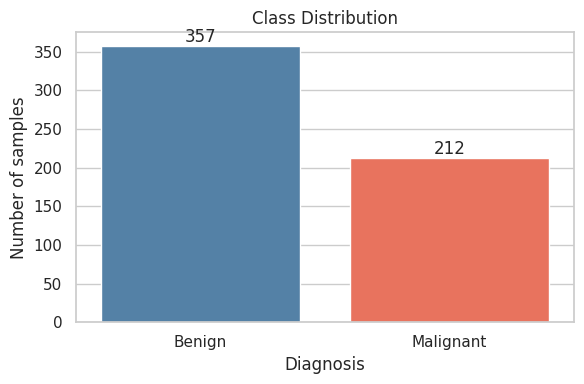

In [ ]:
# =========================================================
# 4. 클래스 분포 시각화
# =========================================================

class_counts = y.value_counts().sort_index()

class_df = pd.DataFrame({
    "Class": ["Benign", "Malignant"],
    "Count": [
        class_counts.loc[0],
        class_counts.loc[1]
    ]
})

plt.figure(figsize=(6, 4))

ax = sns.barplot(
    data=class_df,
    x="Class",
    y="Count",
    hue="Class",
    palette=["steelblue", "tomato"],
    legend=False
)

for container in ax.containers:
    ax.bar_label(container)

plt.title("Class Distribution")
plt.xlabel("Diagnosis")
plt.ylabel("Number of samples")
plt.tight_layout()
plt.show()



전체 데이터를 다음과 같이 분할합니다.

학습 데이터: 80%
테스트 데이터: 20%
클래스 비율 유지: stratify=y
난수 시드: 42

In [ ]:
# =========================================================
# 5. Stratified Hold-out 분할
# =========================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("학습 데이터 크기:", X_train.shape)
print("테스트 데이터 크기:", X_test.shape)

print("\n전체 데이터 악성 비율:")
print(f"{y.mean():.4f}")

print("\n학습 데이터 악성 비율:")
print(f"{y_train.mean():.4f}")

print("\n테스트 데이터 악성 비율:")
print(f"{y_test.mean():.4f}")


학습 데이터 크기: (455, 30)
테스트 데이터 크기: (114, 30)

전체 데이터 악성 비율:
0.3726

학습 데이터 악성 비율:
0.3736

테스트 데이터 악성 비율:
0.3684


In [ ]:
# =========================================================
# 6. 모델 정의
# =========================================================

models = {
    "Decision Tree": Pipeline([
        (
            "model",
            DecisionTreeClassifier(
                max_depth=4,
                min_samples_leaf=5,
                random_state=RANDOM_STATE
            )
        )
    ]),

    "SVM": Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "model",
            SVC(
                kernel="rbf",
                C=1.0,
                gamma="scale"
            )
        )
    ]),

    "Random Forest": Pipeline([
        (
            "model",
            RandomForestClassifier(
                n_estimators=200,
                random_state=RANDOM_STATE,
                n_jobs=-1
            )
        )
    ]),

    "LightGBM": Pipeline([
        (
            "model",
            LGBMClassifier(
                n_estimators=200,
                learning_rate=0.05,
                num_leaves=15,
                random_state=RANDOM_STATE,
                n_jobs=-1,
                verbosity=-1
            )
        )
    ])
}


In [ ]:
# =========================================================
# 7. 모델 학습 및 평가
# =========================================================

results = []
fitted_models = {}
predictions = {}
scores = {}

for model_name, model in models.items():

    # 학습 시간 측정 시작
    start_time = time.perf_counter()

    # 모델 학습
    model.fit(X_train, y_train)

    # 학습 시간 계산
    fit_time = time.perf_counter() - start_time

    # 학습 데이터와 테스트 데이터 예측
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    # ROC-AUC와 Average Precision을 위한 연속 점수
    if hasattr(model, "predict_proba"):
        y_test_score = model.predict_proba(X_test)[:, 1]
    else:
        y_test_score = model.decision_function(X_test)

    # 결과 저장
    fitted_models[model_name] = model
    predictions[model_name] = y_test_pred
    scores[model_name] = y_test_score

    result = {
        "Model": model_name,

        # 과적합 확인용
        "Train Accuracy": accuracy_score(
            y_train, y_train_pred
        ),

        # 테스트 성능
        "Test Accuracy": accuracy_score(
            y_test, y_test_pred
        ),
        "Precision": precision_score(
            y_test,
            y_test_pred,
            zero_division=0
        ),
        "Recall": recall_score(
            y_test,
            y_test_pred,
            zero_division=0
        ),
        "F1-score": f1_score(
            y_test,
            y_test_pred,
            zero_division=0
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            y_test,
            y_test_pred
        ),
        "ROC-AUC": roc_auc_score(
            y_test,
            y_test_score
        ),
        "Average Precision": average_precision_score(
            y_test,
            y_test_score
        ),
        "Fit Time (sec)": fit_time
    }

    results.append(result)
    print(f"\n학습 완료: {model_name}")

print(f"\n학습 완료: 전체")


학습 완료: Decision Tree

학습 완료: SVM

학습 완료: Random Forest

학습 완료: LightGBM

학습 완료: 전체


In [ ]:
# =========================================================
# 8. 성능 비교표
# =========================================================

results_df = pd.DataFrame(results)

# F1-score가 높은 순서로 정렬
results_df = results_df.sort_values(
    by="F1-score",
    ascending=False
).reset_index(drop=True)

pd.set_option("display.max_columns", None)

print("\n모델 성능 비교")
print(results_df.round(4))



모델 성능 비교
           Model  Train Accuracy  Test Accuracy  Precision  Recall  F1-score  \
0            SVM          0.9868         0.9737     1.0000  0.9286    0.9630   
1  Random Forest          1.0000         0.9649     1.0000  0.9048    0.9500   
2       LightGBM          1.0000         0.9649     1.0000  0.9048    0.9500   
3  Decision Tree          0.9626         0.9035     0.9189  0.8095    0.8608   

   Balanced Accuracy  ROC-AUC  Average Precision  Fit Time (sec)  
0             0.9643   0.9947             0.9927          0.0186  
1             0.9524   0.9942             0.9911          0.9706  
2             0.9524   0.9950             0.9937          0.3878  
3             0.8839   0.9153             0.8781          0.0156  


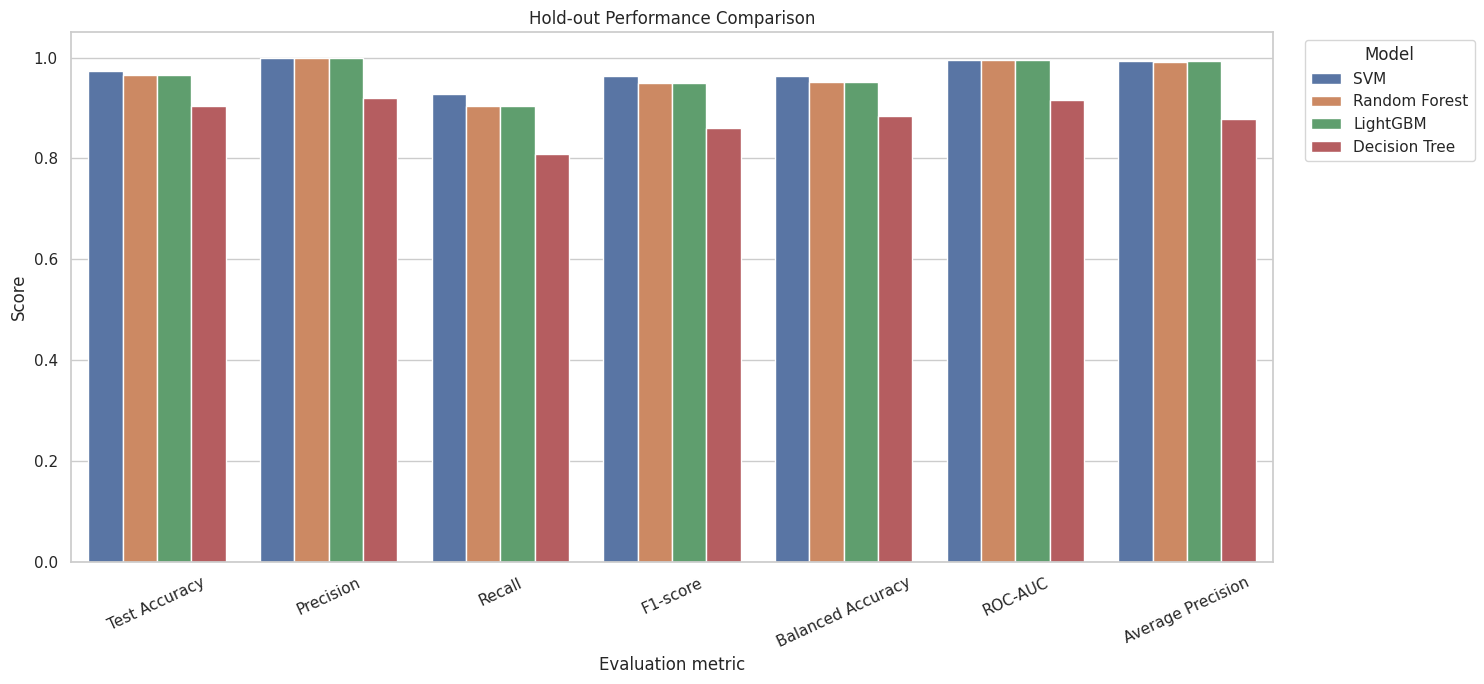

In [ ]:
# =========================================================
# 9. 평가 지표 시각화
# =========================================================

metrics = [
    "Test Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "Balanced Accuracy",
    "ROC-AUC",
    "Average Precision"
]

plot_df = results_df.melt(
    id_vars="Model",
    value_vars=metrics,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(15, 7))

sns.barplot(
    data=plot_df,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.ylim(0, 1.05)
plt.title("Hold-out Performance Comparison")
plt.xlabel("Evaluation metric")
plt.ylabel("Score")
plt.xticks(rotation=25)
plt.legend(
    title="Model",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()


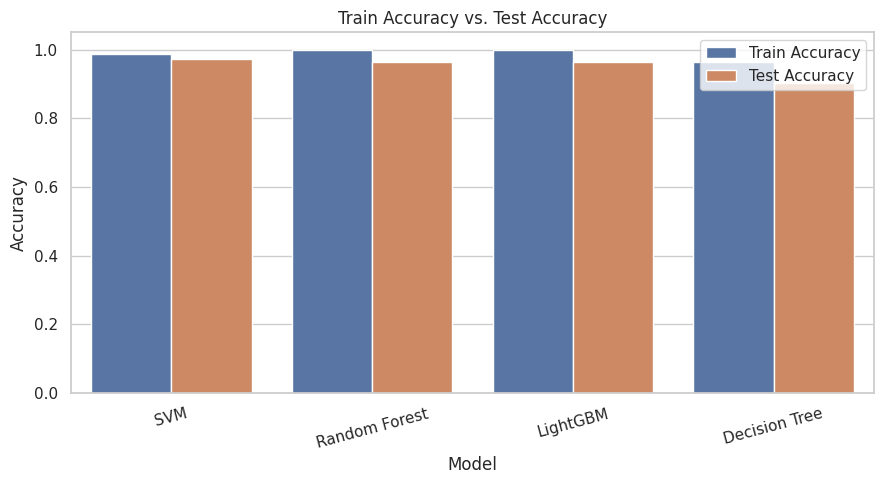

In [ ]:
# =========================================================
# 10. 학습 정확도와 테스트 정확도 비교
# =========================================================

accuracy_df = results_df[
    ["Model", "Train Accuracy", "Test Accuracy"]
].melt(
    id_vars="Model",
    var_name="Dataset",
    value_name="Accuracy"
)

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=accuracy_df,
    x="Model",
    y="Accuracy",
    hue="Dataset"
)

plt.ylim(0, 1.05)
plt.title("Train Accuracy vs. Test Accuracy")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.xticks(rotation=15)
plt.legend(title="")
plt.tight_layout()
plt.show()


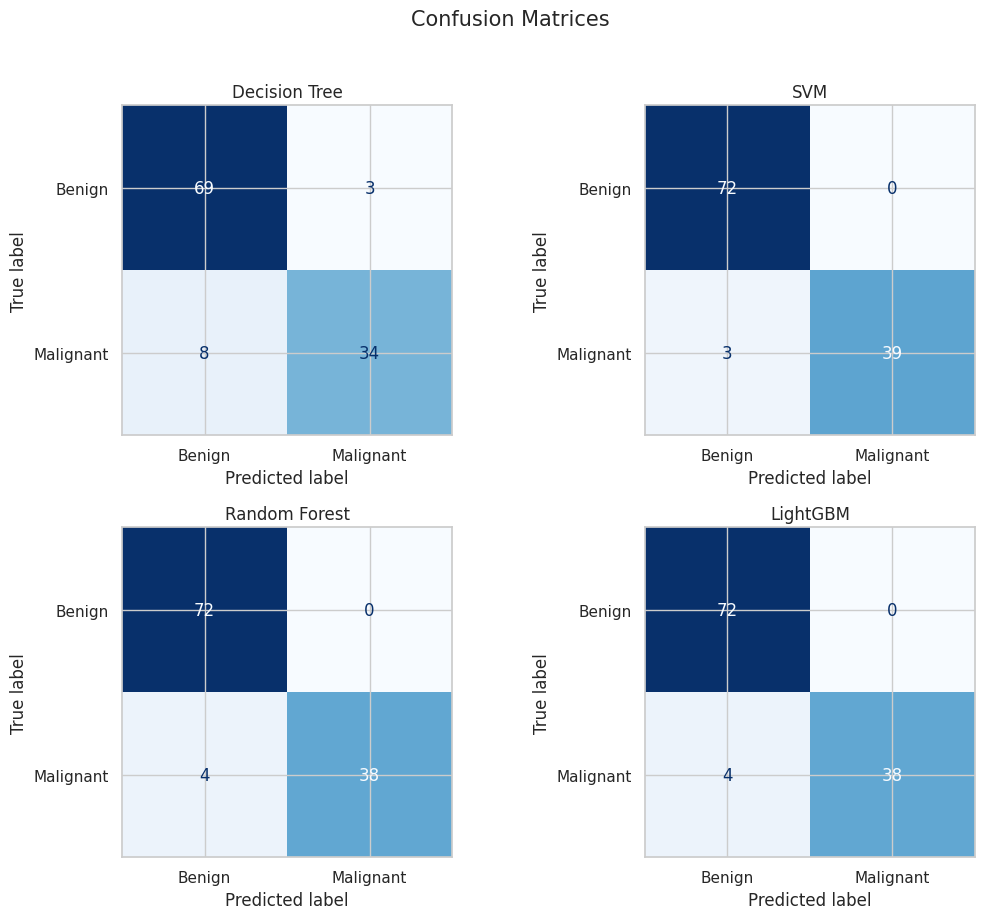

In [ ]:
# =========================================================
# 11. Confusion Matrix 비교
# =========================================================

fig, axes = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(11, 9)
)

axes = axes.ravel()

for ax, model_name in zip(axes, models.keys()):

    y_test_pred = predictions[model_name]

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_test_pred,
        display_labels=["Benign", "Malignant"],
        cmap="Blues",
        colorbar=False,
        ax=ax
    )

    ax.set_title(model_name)

plt.suptitle(
    "Confusion Matrices",
    fontsize=15,
    y=1.02
)

plt.tight_layout()
plt.show()


In [ ]:
# =========================================================
# 12. 모델별 Classification Report
# =========================================================

for model_name in models.keys():

    print("=" * 70)
    print(model_name)
    print("=" * 70)

    print(
        classification_report(
            y_test,
            predictions[model_name],
            target_names=["Benign", "Malignant"],
            digits=4,
            zero_division=0
        )
    )


Decision Tree
              precision    recall  f1-score   support

      Benign     0.8961    0.9583    0.9262        72
   Malignant     0.9189    0.8095    0.8608        42

    accuracy                         0.9035       114
   macro avg     0.9075    0.8839    0.8935       114
weighted avg     0.9045    0.9035    0.9021       114

SVM
              precision    recall  f1-score   support

      Benign     0.9600    1.0000    0.9796        72
   Malignant     1.0000    0.9286    0.9630        42

    accuracy                         0.9737       114
   macro avg     0.9800    0.9643    0.9713       114
weighted avg     0.9747    0.9737    0.9735       114

Random Forest
              precision    recall  f1-score   support

      Benign     0.9474    1.0000    0.9730        72
   Malignant     1.0000    0.9048    0.9500        42

    accuracy                         0.9649       114
   macro avg     0.9737    0.9524    0.9615       114
weighted avg     0.9668    0.9649    0.964

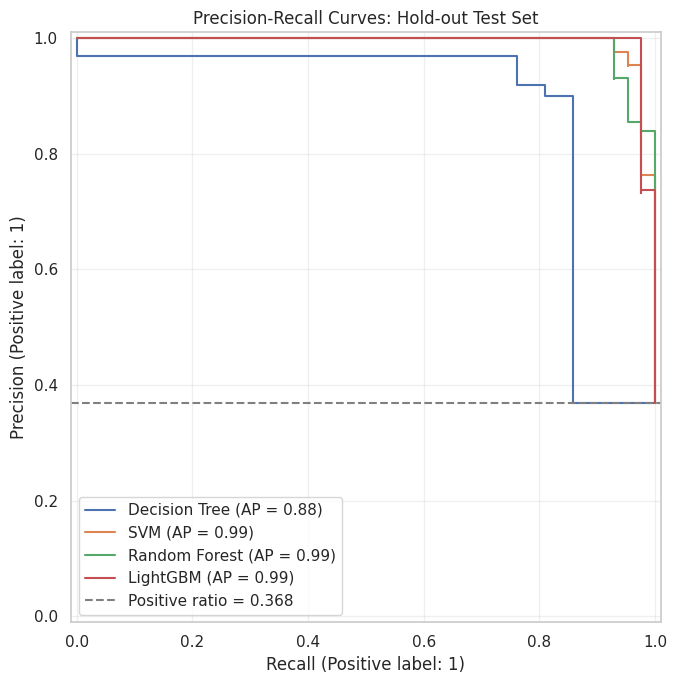

In [ ]:
# =========================================================
# 14. Precision-Recall Curve 비교
# =========================================================

fig, ax = plt.subplots(figsize=(8, 7))

for model_name, model in fitted_models.items():

    PrecisionRecallDisplay.from_estimator(
        model,
        X_test,
        y_test,
        name=model_name,
        ax=ax
    )

# 무작위 분류기의 기준선
positive_ratio = y_test.mean()

ax.axhline(
    positive_ratio,
    linestyle="--",
    color="gray",
    label=f"Positive ratio = {positive_ratio:.3f}"
)

ax.set_title("Precision-Recall Curves: Hold-out Test Set")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()


## 3차 실습: 같은 데이터로 k-fold CV 적용

Breast Cancer 데이터에 5-fold Cross-validation 적용

이번 실습에서는 한 번만 데이터를 나누는 hold-out 대신, 데이터를 5개 fold로 나누어 모든 표본이 한 번씩 검증 데이터가 되도록 합니다.

분류 문제이고 클래스 비율이 약 63:37이므로 일반 KFold보다 StratifiedKFold를 사용합니다.



In [ ]:
# =========================================================
# 1. 라이브러리 불러오기
# =========================================================

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate,
    cross_val_predict
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from lightgbm import LGBMClassifier

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    average_precision_score,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42


In [ ]:
# =========================================================
# 2. 데이터 불러오기
# =========================================================

data = load_breast_cancer(as_frame=True)

X = data.data.copy()

# scikit-learn 원본:
# 0 = malignant, 악성
# 1 = benign, 양성
#
# 악성을 관심 클래스 1로 변경
y = (data.target == 0).astype(int)
y.name = "malignant"

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\n클래스 분포:")
print(y.value_counts().sort_index())

print("\n클래스 비율:")
print(y.value_counts(normalize=True).sort_index())


X shape: (569, 30)
y shape: (569,)

클래스 분포:
malignant
0    357
1    212
Name: count, dtype: int64

클래스 비율:
malignant
0    0.627417
1    0.372583
Name: proportion, dtype: float64


In [ ]:
# =========================================================
# 3. Stratified 5-fold CV 설정
# =========================================================

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

print(cv)


StratifiedKFold(n_splits=5, random_state=42, shuffle=True)


In [ ]:
# =========================================================
# 4. Fold별 데이터 크기와 클래스 비율 확인
# =========================================================

fold_distribution = []

for fold_number, (train_idx, valid_idx) in enumerate(
    cv.split(X, y),
    start=1
):
    y_train_fold = y.iloc[train_idx]
    y_valid_fold = y.iloc[valid_idx]

    fold_distribution.append({
        "Fold": fold_number,
        "Train Size": len(train_idx),
        "Validation Size": len(valid_idx),
        "Train Malignant Ratio": y_train_fold.mean(),
        "Validation Malignant Ratio": y_valid_fold.mean()
    })

fold_distribution_df = pd.DataFrame(fold_distribution)

print(fold_distribution_df.round(4))


   Fold  Train Size  Validation Size  Train Malignant Ratio  \
0     1         455              114                 0.3714   
1     2         455              114                 0.3714   
2     3         455              114                 0.3736   
3     4         455              114                 0.3736   
4     5         456              113                 0.3728   

   Validation Malignant Ratio  
0                      0.3772  
1                      0.3772  
2                      0.3684  
3                      0.3684  
4                      0.3717  


In [ ]:
# =========================================================
# 5. 모델 정의
# =========================================================

models = {
    "Decision Tree": Pipeline([
        (
            "model",
            DecisionTreeClassifier(
                max_depth=4,
                min_samples_leaf=5,
                random_state=RANDOM_STATE
            )
        )
    ]),

    "SVM": Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "model",
            SVC(
                kernel="rbf",
                C=1.0,
                gamma="scale"
            )
        )
    ]),

    "Random Forest": Pipeline([
        (
            "model",
            RandomForestClassifier(
                n_estimators=200,
                random_state=RANDOM_STATE,
                n_jobs=1
            )
        )
    ]),

    "LightGBM": Pipeline([
        (
            "model",
            LGBMClassifier(
                n_estimators=200,
                learning_rate=0.05,
                num_leaves=15,
                random_state=RANDOM_STATE,
                n_jobs=1,
                verbosity=-1
            )
        )
    ])
}


In [ ]:
# =========================================================
# 6. 평가 지표 설정
# =========================================================

scoring = {
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1": "f1",
    "Balanced Accuracy": "balanced_accuracy",
    "ROC-AUC": "roc_auc",
    "Average Precision": "average_precision"
}


In [ ]:
# =========================================================
# 7. 5-fold CV 실행
# =========================================================

summary_results = []
fold_results = []

for model_name, model in models.items():

    print(f"교차검증 중: {model_name}")

    cv_result = cross_validate(
        estimator=model,
        X=X,
        y=y,
        cv=cv,
        scoring=scoring,
        return_train_score=True,
        n_jobs=-1
    )

    # 모델별 평균과 표준편차
    result_row = {
        "Model": model_name,
        "Train Accuracy Mean": cv_result[
            "train_Accuracy"
        ].mean(),
        "CV Accuracy Mean": cv_result[
            "test_Accuracy"
        ].mean(),
        "CV Accuracy Std": cv_result[
            "test_Accuracy"
        ].std(),
        "Precision Mean": cv_result[
            "test_Precision"
        ].mean(),
        "Precision Std": cv_result[
            "test_Precision"
        ].std(),
        "Recall Mean": cv_result[
            "test_Recall"
        ].mean(),
        "Recall Std": cv_result[
            "test_Recall"
        ].std(),
        "F1 Mean": cv_result[
            "test_F1"
        ].mean(),
        "F1 Std": cv_result[
            "test_F1"
        ].std(),
        "Balanced Accuracy Mean": cv_result[
            "test_Balanced Accuracy"
        ].mean(),
        "Balanced Accuracy Std": cv_result[
            "test_Balanced Accuracy"
        ].std(),
        "ROC-AUC Mean": cv_result[
            "test_ROC-AUC"
        ].mean(),
        "ROC-AUC Std": cv_result[
            "test_ROC-AUC"
        ].std(),
        "Average Precision Mean": cv_result[
            "test_Average Precision"
        ].mean(),
        "Average Precision Std": cv_result[
            "test_Average Precision"
        ].std(),
        "Fit Time Mean": cv_result["fit_time"].mean()
    }

    summary_results.append(result_row)

    # 그래프 작성을 위한 fold별 결과
    for fold_index in range(cv.get_n_splits()):

        fold_results.append({
            "Model": model_name,
            "Fold": fold_index + 1,
            "Accuracy": cv_result[
                "test_Accuracy"
            ][fold_index],
            "Precision": cv_result[
                "test_Precision"
            ][fold_index],
            "Recall": cv_result[
                "test_Recall"
            ][fold_index],
            "F1": cv_result[
                "test_F1"
            ][fold_index],
            "Balanced Accuracy": cv_result[
                "test_Balanced Accuracy"
            ][fold_index],
            "ROC-AUC": cv_result[
                "test_ROC-AUC"
            ][fold_index],
            "Average Precision": cv_result[
                "test_Average Precision"
            ][fold_index]
        })


교차검증 중: Decision Tree
교차검증 중: SVM
교차검증 중: Random Forest
교차검증 중: LightGBM


In [ ]:
# =========================================================
# 8. CV 결과표 출력
# =========================================================

cv_summary_df = pd.DataFrame(summary_results)

cv_summary_df = cv_summary_df.sort_values(
    by="F1 Mean",
    ascending=False
).reset_index(drop=True)

pd.set_option("display.max_columns", None)

print(cv_summary_df.round(4))


           Model  Train Accuracy Mean  CV Accuracy Mean  CV Accuracy Std  \
0            SVM               0.9864            0.9772           0.0163   
1       LightGBM               1.0000            0.9701           0.0204   
2  Random Forest               1.0000            0.9543           0.0102   
3  Decision Tree               0.9745            0.9262           0.0251   

   Precision Mean  Precision Std  Recall Mean  Recall Std  F1 Mean  F1 Std  \
0          0.9810         0.0181       0.9576      0.0375   0.9688  0.0222   
1          0.9803         0.0177       0.9386      0.0484   0.9584  0.0289   
2          0.9463         0.0390       0.9341      0.0499   0.9382  0.0146   
3          0.9154         0.0346       0.8872      0.0810   0.8981  0.0395   

   Balanced Accuracy Mean  Balanced Accuracy Std  ROC-AUC Mean  ROC-AUC Std  \
0                  0.9732                 0.0201        0.9945       0.0060   
1                  0.9637                 0.0258        0.9926       0

평균 성능: 평균이 높을수록 전체적으로 좋은 성능을 보인 모델입니다.

표준편차가 작을수록 fold 분할에 따른 성능 변화가 작고 안정적인 모델입니다.

In [ ]:
# =========================================================
# 9. 평균 ± 표준편차 형식의 결과표
# =========================================================

formatted_results = pd.DataFrame({
    "Model": cv_summary_df["Model"],

    "Accuracy": (
        cv_summary_df["CV Accuracy Mean"].map("{:.4f}".format)
        + " ± "
        + cv_summary_df["CV Accuracy Std"].map("{:.4f}".format)
    ),

    "Precision": (
        cv_summary_df["Precision Mean"].map("{:.4f}".format)
        + " ± "
        + cv_summary_df["Precision Std"].map("{:.4f}".format)
    ),

    "Recall": (
        cv_summary_df["Recall Mean"].map("{:.4f}".format)
        + " ± "
        + cv_summary_df["Recall Std"].map("{:.4f}".format)
    ),

    "F1": (
        cv_summary_df["F1 Mean"].map("{:.4f}".format)
        + " ± "
        + cv_summary_df["F1 Std"].map("{:.4f}".format)
    ),

    "Balanced Accuracy": (
        cv_summary_df[
            "Balanced Accuracy Mean"
        ].map("{:.4f}".format)
        + " ± "
        + cv_summary_df[
            "Balanced Accuracy Std"
        ].map("{:.4f}".format)
    ),

    "ROC-AUC": (
        cv_summary_df["ROC-AUC Mean"].map("{:.4f}".format)
        + " ± "
        + cv_summary_df["ROC-AUC Std"].map("{:.4f}".format)
    ),

    "Average Precision": (
        cv_summary_df[
            "Average Precision Mean"
        ].map("{:.4f}".format)
        + " ± "
        + cv_summary_df[
            "Average Precision Std"
        ].map("{:.4f}".format)
    )
})

print(formatted_results.to_string(index=False))


        Model        Accuracy       Precision          Recall              F1 Balanced Accuracy         ROC-AUC Average Precision
          SVM 0.9772 ± 0.0163 0.9810 ± 0.0181 0.9576 ± 0.0375 0.9688 ± 0.0222   0.9732 ± 0.0201 0.9945 ± 0.0060   0.9928 ± 0.0074
     LightGBM 0.9701 ± 0.0204 0.9803 ± 0.0177 0.9386 ± 0.0484 0.9584 ± 0.0289   0.9637 ± 0.0258 0.9926 ± 0.0061   0.9906 ± 0.0071
Random Forest 0.9543 ± 0.0102 0.9463 ± 0.0390 0.9341 ± 0.0499 0.9382 ± 0.0146   0.9503 ± 0.0152 0.9896 ± 0.0077   0.9878 ± 0.0072
Decision Tree 0.9262 ± 0.0251 0.9154 ± 0.0346 0.8872 ± 0.0810 0.8981 ± 0.0395   0.9184 ± 0.0347 0.9419 ± 0.0120   0.9055 ± 0.0232


In [ ]:
# =========================================================
# 10. Fold별 결과 DataFrame
# =========================================================

fold_results_df = pd.DataFrame(fold_results)

print(fold_results_df.head())


           Model  Fold  Accuracy  Precision    Recall        F1  \
0  Decision Tree     1  0.947368   0.911111  0.953488  0.931818   
1  Decision Tree     2  0.877193   0.914286  0.744186  0.820513   
2  Decision Tree     3  0.938596   0.948718  0.880952  0.913580   
3  Decision Tree     4  0.929825   0.854167  0.976190  0.911111   
4  Decision Tree     5  0.938053   0.948718  0.880952  0.913580   

   Balanced Accuracy   ROC-AUC  Average Precision  
0           0.948575  0.955454           0.917599  
1           0.850966  0.927285           0.887441  
2           0.926587  0.941964           0.938585  
3           0.939484  0.955192           0.872603  
4           0.926392  0.929577           0.911369  


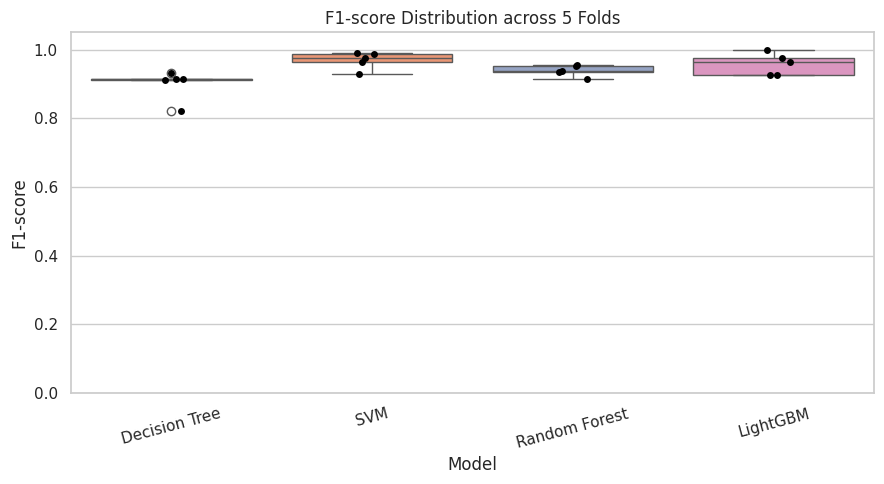

In [ ]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=fold_results_df,
    x="Model",
    y="F1",
    hue="Model",
    palette="Set2",
    legend=False
)

sns.stripplot(
    data=fold_results_df,
    x="Model",
    y="F1",
    color="black",
    size=5,
    jitter=0.08
)

plt.ylim(0, 1.05)
plt.title("F1-score Distribution across 5 Folds")
plt.xlabel("Model")
plt.ylabel("F1-score")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


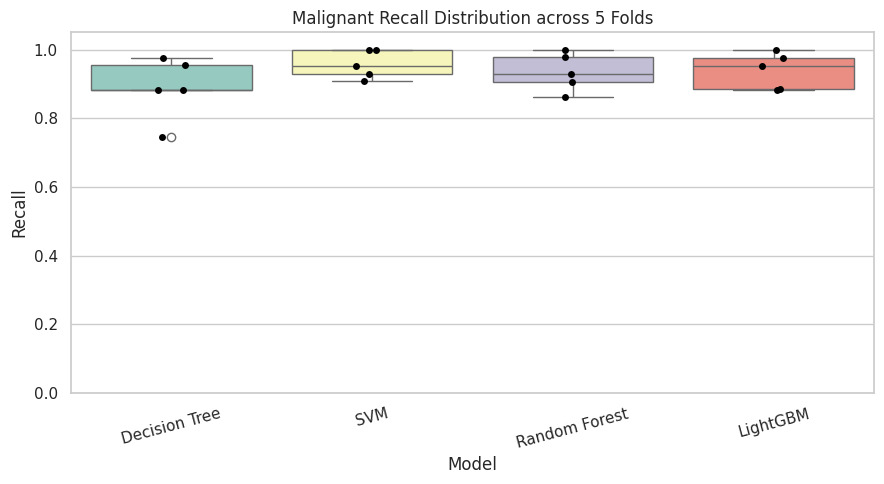

In [ ]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=fold_results_df,
    x="Model",
    y="Recall",
    hue="Model",
    palette="Set3",
    legend=False
)

sns.stripplot(
    data=fold_results_df,
    x="Model",
    y="Recall",
    color="black",
    size=5,
    jitter=0.08
)

plt.ylim(0, 1.05)
plt.title("Malignant Recall Distribution across 5 Folds")
plt.xlabel("Model")
plt.ylabel("Recall")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


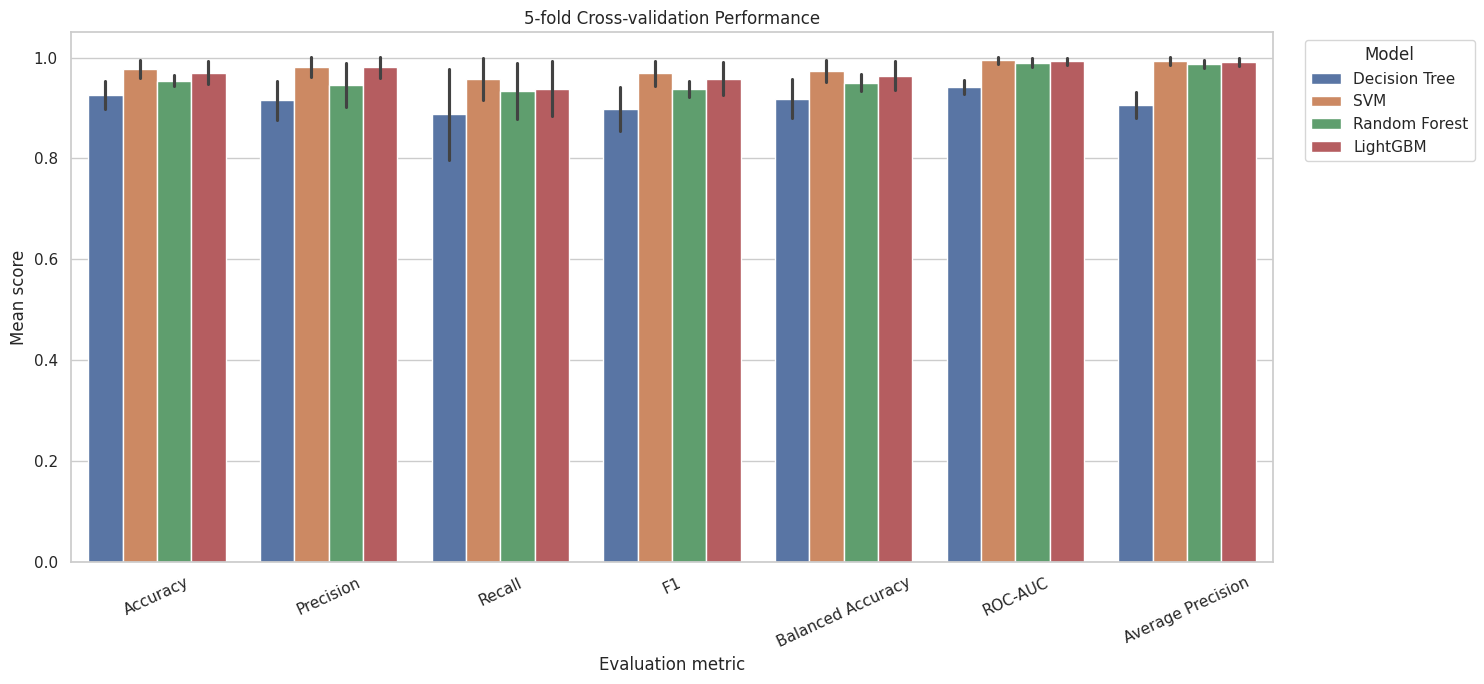

In [ ]:
# =========================================================
# 11. 전체 지표 시각화
# =========================================================

metric_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "Balanced Accuracy",
    "ROC-AUC",
    "Average Precision"
]

long_fold_df = fold_results_df.melt(
    id_vars=["Model", "Fold"],
    value_vars=metric_columns,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(15, 7))

sns.barplot(
    data=long_fold_df,
    x="Metric",
    y="Score",
    hue="Model",
    errorbar="sd"
)

plt.ylim(0, 1.05)
plt.title("5-fold Cross-validation Performance")
plt.xlabel("Evaluation metric")
plt.ylabel("Mean score")
plt.xticks(rotation=25)
plt.legend(
    title="Model",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()


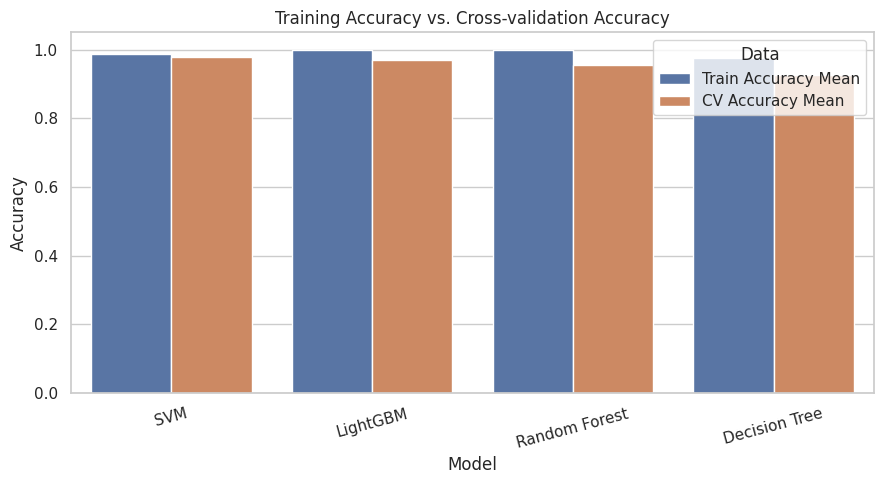

In [ ]:
# =========================================================
# 12. 학습 정확도와 CV 정확도 비교
# =========================================================

train_valid_df = cv_summary_df[
    [
        "Model",
        "Train Accuracy Mean",
        "CV Accuracy Mean"
    ]
].melt(
    id_vars="Model",
    var_name="Data",
    value_name="Accuracy"
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=train_valid_df,
    x="Model",
    y="Accuracy",
    hue="Data"
)

plt.ylim(0, 1.05)
plt.title("Training Accuracy vs. Cross-validation Accuracy")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


## 4차 실습: 같은 데이터로 OVERSAMPLING 적용

In [ ]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from lightgbm import LGBMClassifier

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import (
    RandomOverSampler,
    SMOTE
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42


In [ ]:
# =========================================================
# 1. 데이터 불러오기
# =========================================================


data = load_breast_cancer(as_frame=True)

X = data.data.copy()

# 원본:
# 0 = Malignant
# 1 = Benign
#
# 악성을 관심 클래스 1로 변경
y = (data.target == 0).astype(int)
y.name = "malignant"

print("데이터 크기:", X.shape)

print("\n클래스 분포:")
print(y.value_counts().sort_index())

print("\n클래스 비율:")
print(y.value_counts(normalize=True).sort_index())


데이터 크기: (569, 30)

클래스 분포:
malignant
0    357
1    212
Name: count, dtype: int64

클래스 비율:
malignant
0    0.627417
1    0.372583
Name: proportion, dtype: float64


In [ ]:
# =========================================================
# 2. 최종 테스트 데이터 분리
# =========================================================


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("학습 데이터 크기:", X_train.shape)
print("테스트 데이터 크기:", X_test.shape)

print("\n학습 데이터 클래스 분포:")
print(y_train.value_counts().sort_index())

print("\n테스트 데이터 클래스 분포:")
print(y_test.value_counts().sort_index())


학습 데이터 크기: (455, 30)
테스트 데이터 크기: (114, 30)

학습 데이터 클래스 분포:
malignant
0    285
1    170
Name: count, dtype: int64

테스트 데이터 클래스 분포:
malignant
0    72
1    42
Name: count, dtype: int64


In [ ]:
# =========================================================
# 3. Oversampling 결과 확인
# =========================================================

random_oversampler = RandomOverSampler(
    random_state=RANDOM_STATE
)

X_random_over, y_random_over = (
    random_oversampler.fit_resample(
        X_train,
        y_train
    )
)

smote = SMOTE(
    random_state=RANDOM_STATE,
    k_neighbors=5
)

X_smote, y_smote = smote.fit_resample(
    X_train,
    y_train
)

distribution_df = pd.DataFrame({
    "Original": y_train.value_counts().sort_index(),
    "Random Oversampling": (
        y_random_over.value_counts().sort_index()
    ),
    "SMOTE": y_smote.value_counts().sort_index()
})

distribution_df.index = [
    "Benign",
    "Malignant"
]

print(distribution_df)


           Original  Random Oversampling  SMOTE
Benign          285                  285    285
Malignant       170                  285    285


In [ ]:
models = {
    "Decision Tree": DecisionTreeClassifier(
        max_depth=4,
        min_samples_leaf=5,
        random_state=RANDOM_STATE
    ),

    "SVM": SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale"
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=RANDOM_STATE,
        n_jobs=1
    ),

    "LightGBM": LGBMClassifier(
        n_estimators=200,
        learning_rate=0.05,
        num_leaves=15,
        random_state=RANDOM_STATE,
        n_jobs=1,
        verbosity=-1
    )
}


In [ ]:
sampling_methods = {
    "Original": "passthrough",

    "Random Oversampling": RandomOverSampler(
        random_state=RANDOM_STATE
    ),

    "SMOTE": SMOTE(
        random_state=RANDOM_STATE,
        k_neighbors=5
    )
}


In [ ]:
def make_pipeline(model, sampler):

    return Pipeline([
        (
            "scaler",
            StandardScaler()
        ),
        (
            "sampler",
            sampler
        ),
        (
            "model",
            clone(model)
        )
    ])


In [ ]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)


In [ ]:
scoring = {
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1": "f1",
    "Balanced Accuracy": "balanced_accuracy",
    "ROC-AUC": "roc_auc",
    "Average Precision": "average_precision"
}


In [ ]:
cv_summary = []
cv_fold_results = []

for model_name, model in models.items():

    for sampling_name, sampler in sampling_methods.items():

        print(
            f"실행 중: {model_name} / {sampling_name}"
        )

        pipeline = make_pipeline(
            model=model,
            sampler=sampler
        )

        scores = cross_validate(
            estimator=pipeline,
            X=X_train,
            y=y_train,
            cv=cv,
            scoring=scoring,
            return_train_score=False,
            n_jobs=-1
        )

        cv_summary.append({
            "Model": model_name,
            "Sampling": sampling_name,

            "Accuracy Mean": scores[
                "test_Accuracy"
            ].mean(),
            "Accuracy Std": scores[
                "test_Accuracy"
            ].std(),

            "Precision Mean": scores[
                "test_Precision"
            ].mean(),
            "Precision Std": scores[
                "test_Precision"
            ].std(),

            "Recall Mean": scores[
                "test_Recall"
            ].mean(),
            "Recall Std": scores[
                "test_Recall"
            ].std(),

            "F1 Mean": scores[
                "test_F1"
            ].mean(),
            "F1 Std": scores[
                "test_F1"
            ].std(),

            "Balanced Accuracy Mean": scores[
                "test_Balanced Accuracy"
            ].mean(),
            "Balanced Accuracy Std": scores[
                "test_Balanced Accuracy"
            ].std(),

            "ROC-AUC Mean": scores[
                "test_ROC-AUC"
            ].mean(),
            "ROC-AUC Std": scores[
                "test_ROC-AUC"
            ].std(),

            "Average Precision Mean": scores[
                "test_Average Precision"
            ].mean(),
            "Average Precision Std": scores[
                "test_Average Precision"
            ].std()
        })

        # Fold별 결과 저장
        for fold in range(cv.get_n_splits()):

            cv_fold_results.append({
                "Model": model_name,
                "Sampling": sampling_name,
                "Fold": fold + 1,
                "Accuracy": scores[
                    "test_Accuracy"
                ][fold],
                "Precision": scores[
                    "test_Precision"
                ][fold],
                "Recall": scores[
                    "test_Recall"
                ][fold],
                "F1": scores[
                    "test_F1"
                ][fold],
                "Balanced Accuracy": scores[
                    "test_Balanced Accuracy"
                ][fold],
                "ROC-AUC": scores[
                    "test_ROC-AUC"
                ][fold],
                "Average Precision": scores[
                    "test_Average Precision"
                ][fold]
            })


실행 중: Decision Tree / Original
실행 중: Decision Tree / Random Oversampling
실행 중: Decision Tree / SMOTE
실행 중: SVM / Original
실행 중: SVM / Random Oversampling
실행 중: SVM / SMOTE
실행 중: Random Forest / Original
실행 중: Random Forest / Random Oversampling
실행 중: Random Forest / SMOTE
실행 중: LightGBM / Original
실행 중: LightGBM / Random Oversampling
실행 중: LightGBM / SMOTE


In [ ]:
cv_summary_df = pd.DataFrame(cv_summary)

cv_summary_df = cv_summary_df.sort_values(
    by=["Model", "F1 Mean"],
    ascending=[True, False]
).reset_index(drop=True)

pd.set_option("display.max_columns", None)

print(cv_summary_df.round(4))


            Model             Sampling  Accuracy Mean  Accuracy Std  \
0   Decision Tree  Random Oversampling         0.9297        0.0315   
1   Decision Tree             Original         0.9253        0.0306   
2   Decision Tree                SMOTE         0.9231        0.0070   
3        LightGBM             Original         0.9670        0.0098   
4        LightGBM                SMOTE         0.9670        0.0184   
5        LightGBM  Random Oversampling         0.9626        0.0179   
6   Random Forest  Random Oversampling         0.9648        0.0108   
7   Random Forest             Original         0.9626        0.0149   
8   Random Forest                SMOTE         0.9604        0.0132   
9             SVM                SMOTE         0.9758        0.0108   
10            SVM             Original         0.9714        0.0054   
11            SVM  Random Oversampling         0.9692        0.0082   

    Precision Mean  Precision Std  Recall Mean  Recall Std  F1 Mean  F1 Std 

In [ ]:
simple_cv_result = cv_summary_df[
    [
        "Model",
        "Sampling",
        "Accuracy Mean",
        "Precision Mean",
        "Recall Mean",
        "F1 Mean",
        "Balanced Accuracy Mean",
        "ROC-AUC Mean",
        "Average Precision Mean"
    ]
]

print(simple_cv_result.round(4))


            Model             Sampling  Accuracy Mean  Precision Mean  \
0   Decision Tree  Random Oversampling         0.9297          0.9073   
1   Decision Tree             Original         0.9253          0.9153   
2   Decision Tree                SMOTE         0.9231          0.8977   
3        LightGBM             Original         0.9670          0.9653   
4        LightGBM                SMOTE         0.9670          0.9698   
5        LightGBM  Random Oversampling         0.9626          0.9642   
6   Random Forest  Random Oversampling         0.9648          0.9653   
7   Random Forest             Original         0.9626          0.9638   
8   Random Forest                SMOTE         0.9604          0.9527   
9             SVM                SMOTE         0.9758          0.9709   
10            SVM             Original         0.9714          0.9769   
11            SVM  Random Oversampling         0.9692          0.9646   

    Recall Mean  F1 Mean  Balanced Accuracy Mean  

In [ ]:
# =========================================================
# 원본 대비 성능 변화량 계산
# =========================================================

baseline_df = (
    cv_summary_df[
        cv_summary_df["Sampling"] == "Original"
    ]
    .set_index("Model")
)

comparison_rows = []

for _, row in cv_summary_df.iterrows():

    model_name = row["Model"]
    baseline = baseline_df.loc[model_name]

    comparison_rows.append({
        "Model": model_name,
        "Sampling": row["Sampling"],

        "Accuracy Change": (
            row["Accuracy Mean"]
            - baseline["Accuracy Mean"]
        ),

        "Precision Change": (
            row["Precision Mean"]
            - baseline["Precision Mean"]
        ),

        "Recall Change": (
            row["Recall Mean"]
            - baseline["Recall Mean"]
        ),

        "F1 Change": (
            row["F1 Mean"]
            - baseline["F1 Mean"]
        ),

        "Balanced Accuracy Change": (
            row["Balanced Accuracy Mean"]
            - baseline["Balanced Accuracy Mean"]
        ),

        "ROC-AUC Change": (
            row["ROC-AUC Mean"]
            - baseline["ROC-AUC Mean"]
        ),

        "Average Precision Change": (
            row["Average Precision Mean"]
            - baseline["Average Precision Mean"]
        )
    })

change_df = pd.DataFrame(comparison_rows)

print(
    change_df[
        change_df["Sampling"] != "Original"
    ].round(4)
)


            Model             Sampling  Accuracy Change  Precision Change  \
0   Decision Tree  Random Oversampling           0.0044           -0.0080   
2   Decision Tree                SMOTE          -0.0022           -0.0177   
4        LightGBM                SMOTE           0.0000            0.0045   
5        LightGBM  Random Oversampling          -0.0044           -0.0011   
6   Random Forest  Random Oversampling           0.0022            0.0016   
8   Random Forest                SMOTE          -0.0022           -0.0110   
9             SVM                SMOTE           0.0044           -0.0061   
11            SVM  Random Oversampling          -0.0022           -0.0123   

    Recall Change  F1 Change  Balanced Accuracy Change  ROC-AUC Change  \
0          0.0294     0.0080                    0.0094          0.0128   
2          0.0176    -0.0006                    0.0018          0.0058   
4         -0.0059    -0.0002                   -0.0012         -0.0013   
5         

Recall Change > 0
→ Oversampling 후 악성 종양 탐지율 증가

Precision Change < 0
→ 악성이라고 잘못 판단하는 사례 증가

F1 Change > 0
→ Precision과 Recall을 종합했을 때 개선

Balanced Accuracy Change > 0
→ 양성과 악성의 균형 잡힌 분류 성능 개선

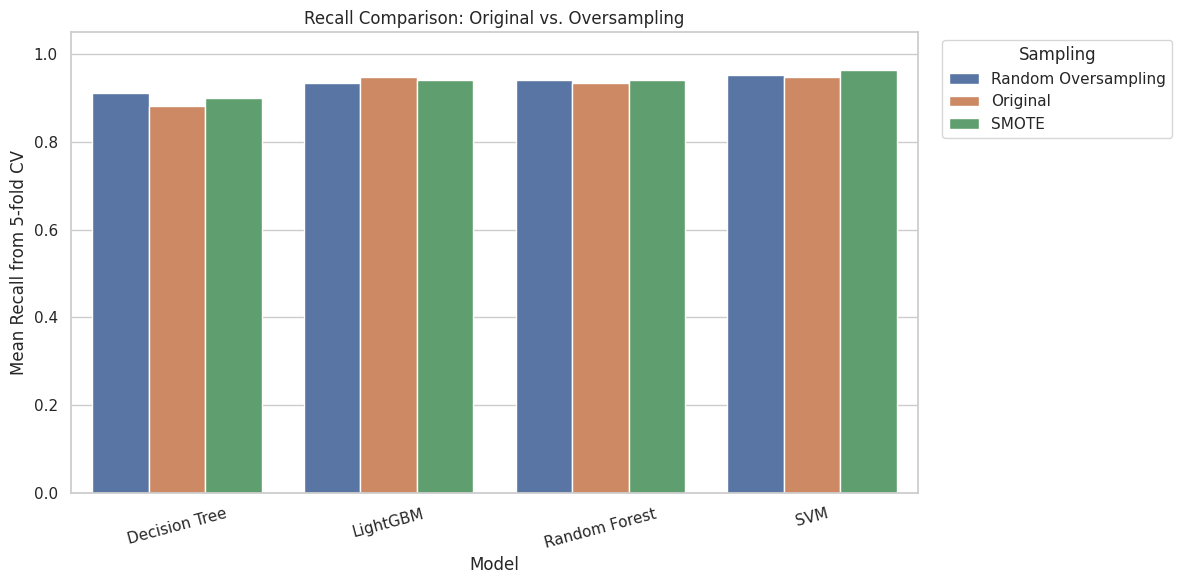

In [ ]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=cv_summary_df,
    x="Model",
    y="Recall Mean",
    hue="Sampling"
)

plt.ylim(0, 1.05)
plt.title("Recall Comparison: Original vs. Oversampling")
plt.xlabel("Model")
plt.ylabel("Mean Recall from 5-fold CV")
plt.xticks(rotation=15)
plt.legend(
    title="Sampling",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()


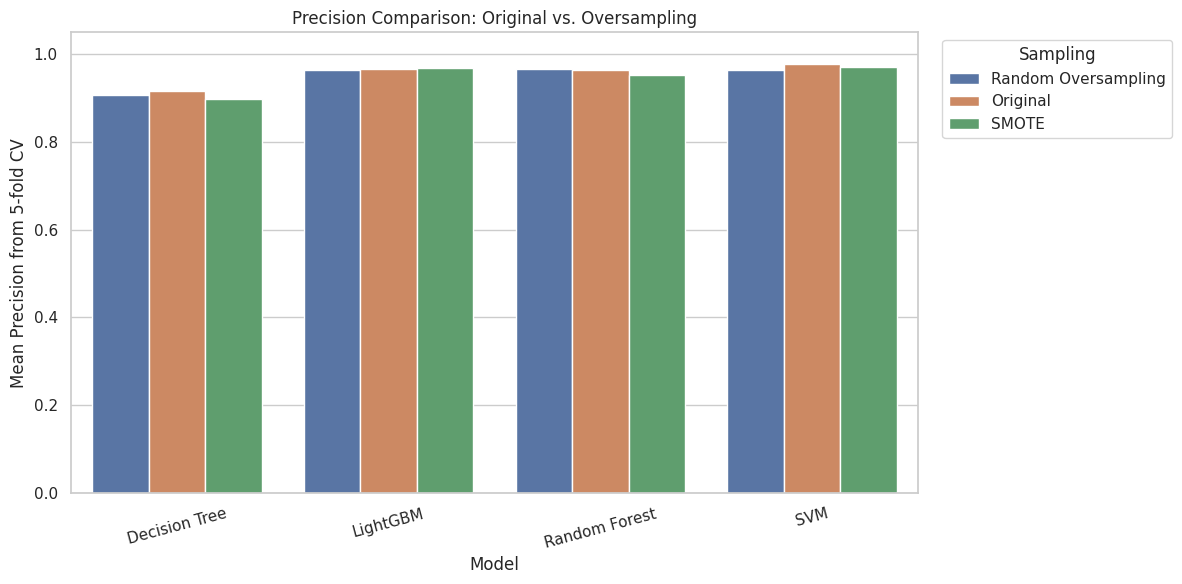

In [ ]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=cv_summary_df,
    x="Model",
    y="Precision Mean",
    hue="Sampling"
)

plt.ylim(0, 1.05)
plt.title(
    "Precision Comparison: Original vs. Oversampling"
)
plt.xlabel("Model")
plt.ylabel("Mean Precision from 5-fold CV")
plt.xticks(rotation=15)
plt.legend(
    title="Sampling",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()


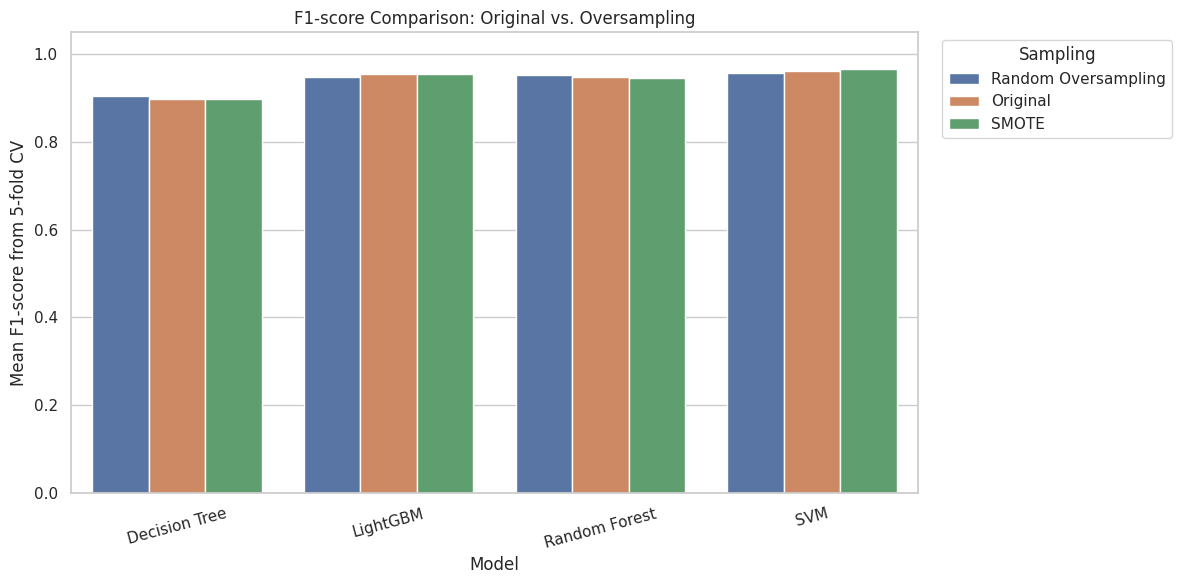

In [ ]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=cv_summary_df,
    x="Model",
    y="F1 Mean",
    hue="Sampling"
)

plt.ylim(0, 1.05)
plt.title(
    "F1-score Comparison: Original vs. Oversampling"
)
plt.xlabel("Model")
plt.ylabel("Mean F1-score from 5-fold CV")
plt.xticks(rotation=15)
plt.legend(
    title="Sampling",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()


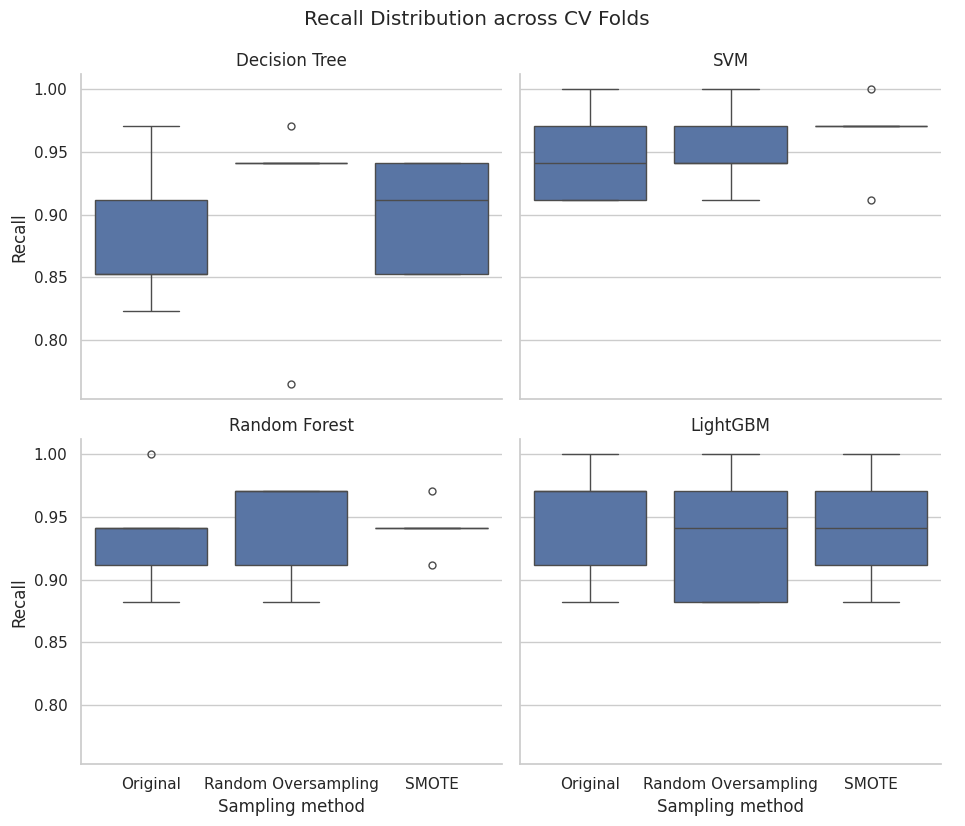

In [ ]:
cv_fold_df = pd.DataFrame(cv_fold_results)

g = sns.catplot(
    data=cv_fold_df,
    x="Sampling",
    y="Recall",
    col="Model",
    kind="box",
    col_wrap=2,
    height=4,
    aspect=1.2,
    sharey=True
)

g.set_axis_labels(
    "Sampling method",
    "Recall"
)

g.set_titles("{col_name}")

g.fig.suptitle(
    "Recall Distribution across CV Folds",
    y=1.03
)

plt.show()


In [ ]:
best_by_f1 = (
    cv_summary_df
    .sort_values(
        by="F1 Mean",
        ascending=False
    )
    .groupby("Model", as_index=False)
    .first()
)

print(
    best_by_f1[
        [
            "Model",
            "Sampling",
            "F1 Mean",
            "Recall Mean",
            "Precision Mean",
            "Balanced Accuracy Mean",
            "ROC-AUC Mean"
        ]
    ].round(4)
)


           Model             Sampling  F1 Mean  Recall Mean  Precision Mean  \
0  Decision Tree  Random Oversampling   0.9059       0.9118          0.9073   
1       LightGBM             Original   0.9551       0.9471          0.9653   
2  Random Forest  Random Oversampling   0.9522       0.9412          0.9653   
3            SVM                SMOTE   0.9674       0.9647          0.9709   

   Balanced Accuracy Mean  ROC-AUC Mean  
0                  0.9261        0.9583  
1                  0.9630        0.9946  
2                  0.9601        0.9906  
3                  0.9736        0.9951  


In [ ]:
best_by_recall = (
    cv_summary_df
    .sort_values(
        by="Recall Mean",
        ascending=False
    )
    .groupby("Model", as_index=False)
    .first()
)

print(
    best_by_recall[
        [
            "Model",
            "Sampling",
            "Recall Mean",
            "Precision Mean",
            "F1 Mean"
        ]
    ].round(4)
)


           Model             Sampling  Recall Mean  Precision Mean  F1 Mean
0  Decision Tree  Random Oversampling       0.9118          0.9073   0.9059
1       LightGBM             Original       0.9471          0.9653   0.9551
2  Random Forest  Random Oversampling       0.9412          0.9653   0.9522
3            SVM                SMOTE       0.9647          0.9709   0.9674


In [ ]:
best_row = cv_summary_df.sort_values(
    by="F1 Mean",
    ascending=False
).iloc[0]

best_model_name = best_row["Model"]
best_sampling_name = best_row["Sampling"]

print("선택 모델:", best_model_name)
print("선택 샘플링:", best_sampling_name)
print("CV F1:", round(best_row["F1 Mean"], 4))


선택 모델: SVM
선택 샘플링: SMOTE
CV F1: 0.9674


In [ ]:
best_model = models[best_model_name]
best_sampler = sampling_methods[best_sampling_name]

best_pipeline = make_pipeline(
    model=best_model,
    sampler=best_sampler
)

# 전체 학습 데이터로 재학습
best_pipeline.fit(
    X_train,
    y_train
)

# 최종 테스트 데이터 평가
y_test_pred = best_pipeline.predict(X_test)

if hasattr(best_pipeline, "predict_proba"):
    y_test_score = best_pipeline.predict_proba(
        X_test
    )[:, 1]
else:
    y_test_score = best_pipeline.decision_function(
        X_test
    )


In [ ]:
final_result = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "Balanced Accuracy",
        "ROC-AUC",
        "Average Precision"
    ],
    "Score": [
        accuracy_score(y_test, y_test_pred),
        precision_score(
            y_test,
            y_test_pred,
            zero_division=0
        ),
        recall_score(
            y_test,
            y_test_pred,
            zero_division=0
        ),
        f1_score(
            y_test,
            y_test_pred,
            zero_division=0
        ),
        balanced_accuracy_score(
            y_test,
            y_test_pred
        ),
        roc_auc_score(
            y_test,
            y_test_score
        ),
        average_precision_score(
            y_test,
            y_test_score
        )
    ]
})

print(final_result.round(4))


              Metric   Score
0           Accuracy  0.9737
1          Precision  0.9756
2             Recall  0.9524
3                 F1  0.9639
4  Balanced Accuracy  0.9692
5            ROC-AUC  0.9957
6  Average Precision  0.9941


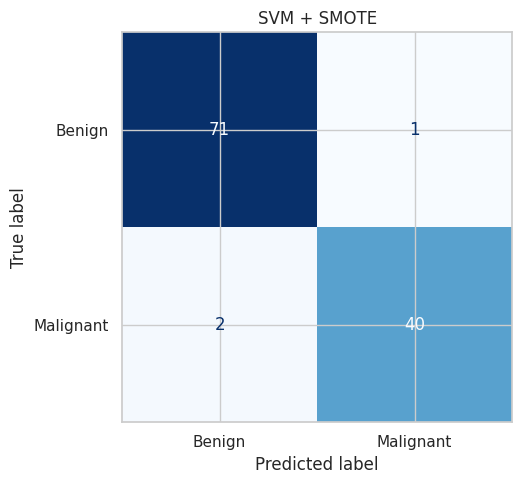

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    display_labels=["Benign", "Malignant"],
    cmap="Blues",
    colorbar=False
)

plt.title(
    f"{best_model_name} + {best_sampling_name}"
)

plt.tight_layout()
plt.show()
